# TP5: Chatbot con LLM y modelos de embeddings (RAG)

**Alumno:** Carlos Alanis
**Materia:** Procesamiento del Habla

**Aplicación:** chatbot de consultas sobre trámites municipales (habilitación comercial), con información del Municipio de Bahía Blanca.

Este notebook parte de una copia del notebook del TP3 y está organizado en dos partes:
- **Parte 1 (TP3):** base de conocimiento (dataset de preguntas y respuestas) y chatbots con TF-IDF y con embeddings de spaCy.
- **Parte 2 (TP5):** consignas a) a g): dataset de evaluación, elección de modelos (LLM y embeddings), clase `ChatBot` con base de datos vectorial, comparación de embeddings, evaluación del retrieval (bonus e) y referencias.

Las fuentes consultadas, incluidas las conversaciones con IA generativa, están en la sección **Referencias** al final del notebook.

## Parte 1: TP3 Chatbots basados en recuperación de la información

En inglés *information retrieval chatbots*

# Motor de búsqueda

* Búsqueda por palabras clave: Extrae palabras clave de la pregunta del usuario y busca coincidencias en las preguntas almacenadas.

* Similitud del coseno: Si has representado las preguntas como vectores (por ejemplo, usando TF-IDF o word embeddings), puedes usar la similitud del coseno para medir la distancia entre las preguntas.

* Embeddings: Utiliza modelos de word embeddings como por ejemplo Word2Vec para obtener representaciones semánticas de las preguntas y las consultas del usuario.

## Librerías

Debes trabajar en Python. Puedes usar las librerías sklearn, pandas, spacy o nltk o gensim para el punto de usar o buscar embeddings.

In [ ]:
!pip install spacy --quiet
!python -m spacy download es_core_news_sm --quiet
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

✔ Download and installation successful
You can now load the package via spacy.load('es_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


## Actividades



### 1) Elaborar un dataset de preguntas y respuestas para crear un Chatbot para un aplicación particular. ( 3 puntos )

1.1 Debe definir la aplicación (atención al cliente bancario, atención a estudiantes universitarios, etc).

1.2 El listado de preguntas y respuestas debe tener como mínimo 20 elementos pregunta - respuesta.

###  2) Crear el chatbot utilizando TFIDF y similitud del coseno. (1 punto)

### 3) Crear otro chatbot utilizando embeddings. Indique cuál embedding (1 punto) pre-entrenado de las librerías Spacy o nltk o gensim eligió. Justifique.

### 4) Muestra ambos chatbots funcionando (1 punto)

Adjuntar la lista de preguntas y respuestas utilizadas para probar el funcionamiento.

Releve o indique cuáles respondió correctamente y cuáles no.

### 5) Añade tus conclusiones de todo lo realizado (2 punto)

* Resalte e indique en cuáles respuestas falla o tiene problemas.
* Cuáles preguntas confunde.
* Compare los resultados de los chatbots.



### No olvides:

* Explicar tus decisiones y configuraciones. Añadir tus conclusiones.
* Anunciar en el foro cuál será tu aplicación y postear tu entrega y tus avances.
* Debes subir tu notebook a un repo GitHub público de tu propiedad compartido + enlace colab.
* Documentar todo el proceso.
* Citar tus fuentes





In [ ]:
# Dataset de preguntas y respuestas: habilitación comercial (Municipio de Bahía Blanca)

# Fuente:
# Municipio de Bahía Blanca. (s. f.). Recomendaciones para realizar el trámite
# Habilitaciones comerciales. https://www.bahia.gob.ar/tramites/habilitaciones/comerciales/recomendaciones-para-realizar-el-tramite/
# Consultado el 11/10/2026.
# Los contenidos de bahia.gob.ar están licenciados bajo Creative Commons

dataset = [
    {
        "pregunta": "¿Qué tengo que verificar antes de hacer la consulta de habilitación comercial?",
        "respuesta": "Que la actividad esté permitida en esa zona según el Código de Planeamiento Urbano, que tengas planos conforme a obra con informe técnico, que el local tenga condiciones edilicias adecuadas, que cumplas los requisitos de la ordenanza específica de tu actividad y que cuentes con la Constancia de Cumplimiento Tributario.",
    },
    {
        "pregunta": "¿Cuánto tiempo es válida la Constancia de Cumplimiento Tributario?",
        "respuesta": "Tiene una validez de 30 días, así que conviene gestionarla cerca del momento de presentar el trámite.",
    },
    {
        "pregunta": "¿Dónde se pide la Constancia de Cumplimiento Tributario?",
        "respuesta": "La emite el Departamento de Recaudación de la Municipalidad y se necesita para la habilitación municipal.",
    },
    {
        "pregunta": "¿Tengo que inscribirme en AFIP y ARBA antes de empezar?",
        "respuesta": "Sí, conviene darte de alta por adelantado: en AFIP para obtener el CUIT, la categoría de contribuyente y los impuestos nacionales, y en ARBA para inscribirte en Ingresos Brutos provincial.",
    },
    {
        "pregunta": "¿Cómo me registro en el sitio para hacer el trámite online?",
        "respuesta": "Tenés que entrar al sitio Mi cuenta ciudadano y darte de alta con tu DNI y una contraseña.",
    },
    {
        "pregunta": "¿Cómo inicio la consulta de habilitación de mi comercio?",
        "respuesta": "Ingresá a Mi cuenta ciudadano, hacé clic en Habilitaciones Comerciales y luego en Nueva consulta de habilitaciones de comercios.",
    },
    {
        "pregunta": "¿Qué datos tengo que cargar en la consulta online?",
        "respuesta": "Los datos comerciales, los integrantes de la razón social, las características edilicias, la actividad que vas a desarrollar y la superficie afectada. Al terminar hay que grabar todo.",
    },
    {
        "pregunta": "¿Cómo me entero si mi consulta de habilitación fue aprobada?",
        "respuesta": "A las 48 horas recibís un aviso que podés leer en la sección Mis avisos de la web, donde se confirma si el trámite fue aprobado o no.",
    },
    {
        "pregunta": "¿Cómo saco turno para presentar la documentación?",
        "respuesta": "Si la consulta fue aprobada, entrás al calendario dentro del sitio y solicitás el turno para ir a Habilitaciones.",
    },
    {
        "pregunta": "¿Qué documentación personal e impositiva debo llevar al turno?",
        "respuesta": "Una fotocopia del DNI del titular y las constancias de inscripción en AFIP y en ARBA.",
    },
    {
        "pregunta": "¿Qué formularios tengo que firmar frente a un funcionario municipal?",
        "respuesta": "El Formulario de Empadronamiento Fiscal y la Declaración de activo fijo. Ambos se firman ante un funcionario de la Municipalidad.",
    },
    {
        "pregunta": "¿Qué plano tengo que presentar para habilitar el local?",
        "respuesta": "El plano civil conforme a obra y a uso con los sellos municipales. Si la construcción no tiene permiso, hay que adjuntar un informe técnico actualizado y visado por el colegio profesional que avale la estabilidad y habitabilidad del inmueble.",
    },
    {
        "pregunta": "¿Qué papel adicional piden si el comercio es una sociedad?",
        "respuesta": "Hay que presentar el contrato social inscripto.",
    },
    {
        "pregunta": "¿Quién tiene que emitir el certificado eléctrico del local?",
        "respuesta": "El Certificado de Aptitud Eléctrica lo debe emitir un electricista matriculado y tiene que estar visado por el colegio profesional correspondiente.",
    },
    {
        "pregunta": "¿Tengo que tener matafuegos en el comercio?",
        "respuesta": "Sí, se pide la oblea de matafuego con la carga vigente.",
    },
    {
        "pregunta": "¿Me piden el carnet de manipulador de alimentos?",
        "respuesta": "Solo si el Departamento de Habilitaciones lo solicita. En ese caso, el curso debe estar cursado y aprobado.",
    },
    {
        "pregunta": "¿En qué casos hace falta un informe de seguridad?",
        "respuesta": "Cuando lo pide el Departamento de Habilitaciones, y debe estar hecho por un profesional matriculado.",
    },
    {
        "pregunta": "¿Dónde pago la tasa de habilitación?",
        "respuesta": "En Recaudación. Ahí también se da de alta el número de contribuyente y se asocian los códigos de las actividades que vas a desarrollar.",
    },
    {
        "pregunta": "¿Qué certificado me entregan al terminar el trámite y cuánto dura?",
        "respuesta": "Te dan un Certificado de Habilitación en trámite, válido por 90 días, hasta que se haga la inspección y se emita el certificado definitivo.",
    },
    {
        "pregunta": "¿Cómo puedo comunicarme con el Municipio para hacer una consulta?",
        "respuesta": "Podés llamar al +54 (291) 459 4000, acercarte a Alsina 65 en Bahía Blanca o usar el formulario de Consultas del sitio web del Municipio.",
    },
]

if __name__ == "__main__":
    print(f"{len(dataset)} pares pregunta-respuesta")

20 pares pregunta-respuesta


## 2) Chatbot con TF-IDF y similitud del coseno

**Idea:** convertir cada pregunta del dataset en un vector TF-IDF. Cuando el
usuario escribe una consulta, se la convierte al mismo espacio vectorial, se
calcula la similitud del coseno contra todas las preguntas del dataset y se
devuelve la respuesta de la pregunta más parecida.

**Decisiones:**
- Preprocesamiento con spaCy (`es_core_news_sm`): minúsculas, tokenización,
  eliminación de stopwords y lematización, para que "habilitar" y
  "habilitación" se parezcan más.
- `strip_accents="unicode"` para que "habilitacion" sin tilde coincida con
  "habilitación".
- Se define un umbral mínimo de similitud: si la mejor coincidencia está por
  debajo, el chatbot dice que no entendió la pregunta en vez de inventar.

In [ ]:
import spacy
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

nlp = spacy.load("es_core_news_sm")


In [ ]:
preguntas = [par["pregunta"] for par in dataset]
respuestas = [par["respuesta"] for par in dataset]


def preprocesar(texto):
    """Minúsculas, tokeniza, quita stopwords/puntuación y lematiza."""
    doc = nlp(texto.lower())
    tokens = [t.lemma_ for t in doc if t.is_alpha and not t.is_stop]
    return " ".join(tokens)


preguntas_proc = [preprocesar(p) for p in preguntas]

# Para ver cómo quedaron las primeras preguntas después del preprocesamiento
for original, procesada in list(zip(preguntas, preguntas_proc))[:3]:
    print("Original :", original)
    print("Procesada:", procesada)
    print()


Original : ¿Qué tengo que verificar antes de hacer la consulta de habilitación comercial?
Procesada: verificar consulta habilitación comercial

Original : ¿Cuánto tiempo es válida la Constancia de Cumplimiento Tributario?
Procesada: tiempo válido constancia cumplimiento tributario

Original : ¿Dónde se pide la Constancia de Cumplimiento Tributario?
Procesada: pedir constancia cumplimiento tributario



In [ ]:
vectorizador = TfidfVectorizer(strip_accents="unicode")
matriz_tfidf = vectorizador.fit_transform(preguntas_proc)

print("Forma de la matriz TF-IDF (preguntas x términos):", matriz_tfidf.shape)
print("Cantidad de términos en el vocabulario:", len(vectorizador.vocabulary_))


Forma de la matriz TF-IDF (preguntas x términos): (20, 61)
Cantidad de términos en el vocabulario: 61


In [ ]:
UMBRAL = 0.20  # similitud mínima para considerar que entendió la pregunta
MENSAJE_NO_ENTENDI = (
    "Lo siento, no encontré una respuesta para tu pregunta. "
    "¿Podrías reformularla?"
)


def chatbot_tfidf(consulta, umbral=UMBRAL):
    """Devuelve (respuesta, pregunta_más_parecida, similitud)."""
    consulta_proc = preprocesar(consulta)
    vector_consulta = vectorizador.transform([consulta_proc])
    similitudes = cosine_similarity(vector_consulta, matriz_tfidf)[0]

    mejor = similitudes.argmax()
    puntaje = float(similitudes[mejor])

    if puntaje < umbral:
        return MENSAJE_NO_ENTENDI, None, puntaje
    return respuestas[mejor], preguntas[mejor], puntaje

In [ ]:
ejemplos = [
    "¿Cuánto dura la constancia de cumplimiento tributario?",
    "Como pido turno para llevar los papeles",
    "¿Cuál es la capital de Francia?",
]

for consulta in ejemplos:
    respuesta, coincidencia, puntaje = chatbot_tfidf(consulta)
    print(f"Usuario  : {consulta}")
    print(f"Coincide : {coincidencia}")
    print(f"Similitud: {puntaje:.3f}")
    print(f"Chatbot  : {respuesta}")
    print("-" * 60)

Usuario  : ¿Cuánto dura la constancia de cumplimiento tributario?
Coincide : ¿Dónde se pide la Constancia de Cumplimiento Tributario?
Similitud: 0.887
Chatbot  : La emite el Departamento de Recaudación de la Municipalidad y se necesita para la habilitación municipal.
------------------------------------------------------------
Usuario  : Como pido turno para llevar los papeles
Coincide : ¿Qué papel adicional piden si el comercio es una sociedad?
Similitud: 0.509
Chatbot  : Hay que presentar el contrato social inscripto.
------------------------------------------------------------
Usuario  : ¿Cuál es la capital de Francia?
Coincide : None
Similitud: 0.000
Chatbot  : Lo siento, no encontré una respuesta para tu pregunta. ¿Podrías reformularla?
------------------------------------------------------------


In [ ]:
def chatear_tfidf():
    print("Chatbot de habilitación comercial (TF-IDF). Escribí 'salir' para terminar.")
    while True:
        consulta = input("Vos: ")
        if consulta.strip().lower() in ("salir", "exit", "chau"):
            print("Chatbot: ¡Hasta luego!")
            break
        respuesta, _, _ = chatbot_tfidf(consulta)
        print("Chatbot:", respuesta)

chatear_tfidf()

Chatbot de habilitación comercial (TF-IDF). Escribí 'salir' para terminar.
Vos: salir
Chatbot: ¡Hasta luego!


## 3) Chatbot con embeddings

**Embedding elegido:** vectores de palabras preentrenados de spaCy en español,
modelo `es_core_news_md` (vectores de 300 dimensiones).

**Justificación:**
- Está entrenado en **español**, el mismo idioma que mi dataset. Usar embeddings
  de otro idioma no tendría sentido, porque las palabras no estarían en su vocabulario.
- Es **preentrenado**: mi dataset tiene solo 20 preguntas, muy pocos datos para
  entrenar o ajustar (fine-tuning) mis propios embeddings.
- Es un modelo **mediano**: trae vectores reales de palabras (el `es_core_news_sm`
  del template no los trae, por eso no sirve para este paso) y es liviano para Colab.
  El `es_core_news_lg` es más grande y pesado, y para un dataset tan chico
  no hace falta.
- Son embeddings **estáticos** (un vector por palabra, como Word2Vec/GloVe/FastText):
  no distinguen polisemia y las palabras fuera del vocabulario quedan sin vector.

**Cómo funciona el chatbot:**
1. Cada pregunta se convierte en un vector: el **promedio** de los vectores de sus
   palabras (sin stopwords ni signos de puntuación).
2. Se calcula la **similitud del coseno** entre el vector de la consulta y el de
   cada pregunta del dataset.
3. Se devuelve la respuesta de la pregunta más parecida, salvo que la similitud no
   supere un umbral mínimo.

In [ ]:
!python -m spacy download es_core_news_md --quiet

✔ Download and installation successful
You can now load the package via spacy.load('es_core_news_md')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
import numpy as np
import spacy
from sklearn.metrics.pairwise import cosine_similarity

nlp_emb = spacy.load("es_core_news_md")

print("Dimensión de los vectores:", nlp_emb.vocab.vectors.shape[1])

Dimensión de los vectores: 300


In [ ]:
def vectorizar(texto):
    """Promedio de los vectores de las palabras (sin stopwords) de un texto."""
    doc = nlp_emb(texto.lower())
    vectores = [t.vector for t in doc if t.is_alpha and not t.is_stop and t.has_vector]
    if vectores:
        return np.mean(vectores, axis=0)
    return doc.vector  # si no quedó ninguna palabra útil, usa el vector del documento


matriz_emb = np.array([vectorizar(p) for p in preguntas])
print("Forma de la matriz de embeddings (preguntas x dimensiones):", matriz_emb.shape)

Forma de la matriz de embeddings (preguntas x dimensiones): (20, 300)


In [ ]:
UMBRAL_EMB = 0.40  # similitud mínima para considerar que entendió la pregunta
MENSAJE_NO_ENTENDI = (
    "Lo siento, no encontré una respuesta para tu pregunta. "
    "¿Podrías reformularla?"
)


def chatbot_embeddings(consulta, umbral=UMBRAL_EMB):
    """Devuelve (respuesta, pregunta_más_parecida, similitud)."""
    vector_consulta = vectorizar(consulta).reshape(1, -1)
    similitudes = cosine_similarity(vector_consulta, matriz_emb)[0]

    mejor = similitudes.argmax()
    puntaje = float(similitudes[mejor])

    if puntaje < umbral:
        return MENSAJE_NO_ENTENDI, None, puntaje
    return respuestas[mejor], preguntas[mejor], puntaje

In [ ]:
ejemplos = [
    "¿Cuánto dura la constancia de cumplimiento tributario?",
    "Como pido turno para llevar los papeles",
    "necesito matafuegos para el local",
    "¿Cuál es la capital de Francia?",
]

for consulta in ejemplos:
    r_tfidf, c_tfidf, s_tfidf = chatbot_tfidf(consulta)
    r_emb, c_emb, s_emb = chatbot_embeddings(consulta)
    print(f"Usuario        : {consulta}")
    print(f"TF-IDF     ({s_tfidf:.2f}): {c_tfidf}")
    print(f"Embeddings ({s_emb:.2f}): {c_emb}")
    print("-" * 70)

Usuario        : ¿Cuánto dura la constancia de cumplimiento tributario?
TF-IDF     (0.89): ¿Dónde se pide la Constancia de Cumplimiento Tributario?
Embeddings (0.88): ¿Cuánto tiempo es válida la Constancia de Cumplimiento Tributario?
----------------------------------------------------------------------
Usuario        : Como pido turno para llevar los papeles
TF-IDF     (0.51): ¿Qué papel adicional piden si el comercio es una sociedad?
Embeddings (0.46): ¿Cómo saco turno para presentar la documentación?
----------------------------------------------------------------------
Usuario        : necesito matafuegos para el local
TF-IDF     (0.59): ¿Tengo que tener matafuegos en el comercio?
Embeddings (0.67): ¿Tengo que tener matafuegos en el comercio?
----------------------------------------------------------------------
Usuario        : ¿Cuál es la capital de Francia?
TF-IDF     (0.00): None
Embeddings (0.52): ¿Cómo inicio la consulta de habilitación de mi comercio?
-----------------------

In [ ]:
def chatear_embeddings():
    print("Chatbot de habilitación comercial (embeddings). Escribí 'salir' para terminar.")
    while True:
        consulta = input("Vos: ")
        if consulta.strip().lower() in ("salir", "exit", "chau"):
            print("Chatbot: ¡Hasta luego!")
            break
        respuesta, _, _ = chatbot_embeddings(consulta)
        print("Chatbot:", respuesta)

chatear_embeddings()

Chatbot de habilitación comercial (embeddings). Escribí 'salir' para terminar.
Vos: salir
Chatbot: ¡Hasta luego!


## 4) Ambos chatbots funcionando

Para probar los chatbots armé una lista de **preguntas de prueba nuevas**, que
no están escritas igual en el dataset:
- 20 **paráfrasis**: una por cada pregunta del dataset, dicha con otras palabras
  (sinónimos, orden distinto, sin tildes, etc.).
- 3 preguntas **cortas o escritas informalmente** sobre el mismo tema.
- 6 preguntas **fuera del dataset**: algunas sin relación (capital de Francia, el
  mundial) y otras de tema parecido pero que el dataset no cubre (patente, licencia
  de conducir, horario de atención). El chatbot correcto debería responder que
  no entendió.

Una respuesta se considera **correcta** si el chatbot elige la pregunta del dataset
que corresponde (o, en las preguntas fuera de tema, si rechaza la consulta).

In [ ]:
import pandas as pd

# (consulta de prueba, índice de la pregunta correcta en el dataset o None si está fuera de tema)
pruebas = [
    # --- Paráfrasis (una por cada pregunta del dataset) ---
    ("Qué requisitos básicos tengo que chequear antes de empezar el trámite", 0),
    ("Por cuántos días sirve la constancia tributaria", 1),
    ("Qué oficina entrega la constancia de cumplimiento tributario", 2),
    ("Hace falta tener el CUIT y estar en Ingresos Brutos antes de habilitar", 3),
    ("Cómo creo mi usuario en la página del municipio", 4),
    ("Por dónde empiezo la consulta online para habilitar mi negocio", 5),
    ("Qué información piden completar en el formulario de la consulta", 6),
    ("Cómo averiguo si me aprobaron la consulta", 7),
    ("Cómo reservo un horario para ir a presentar los papeles", 8),
    ("Con qué documentos de identidad e impuestos me presento", 9),
    ("Cuáles son las planillas que firmo en la municipalidad", 10),
    ("Qué planos del local necesito llevar", 11),
    ("Si mi comercio es una sociedad, qué papeles extra necesito", 12),
    ("Qué profesional firma el certificado de la instalación eléctrica", 13),
    ("Es obligatorio tener extintores en el local", 14),
    ("Hay que hacer el curso de manejo de alimentos", 15),
    ("Cuándo me piden un informe de seguridad", 16),
    ("En qué lugar se paga la tasa de habilitación", 17),
    ("Cuántos días vale el certificado provisorio que me dan al final", 18),
    ("Cuál es el teléfono del municipio", 19),
    # --- Preguntas cortas / informales / sin tildes ---
    ("cuanto tiempo es valida la constancia", 1),
    ("matafuegos en el comercio", 14),
    ("donde pago la tasa", 17),
    # --- Fuera del dataset ---
    ("¿Cuál es la capital de Francia?", None),
    ("Hola, buen día", None),
    ("¿Quién ganó el último mundial de fútbol?", None),
    ("¿Cómo se paga la patente de un auto?", None),
    ("Quiero sacar la licencia de conducir", None),
    ("¿A qué hora abre la municipalidad?", None),
]

# Tabla con las preguntas de prueba y la respuesta esperada
df_pruebas = pd.DataFrame(
    {
        "Pregunta de prueba": [p[0] for p in pruebas],
        "Pregunta esperada del dataset": [
            preguntas[p[1]] if p[1] is not None else "(fuera de tema: debe rechazar)"
            for p in pruebas
        ],
        "Respuesta esperada": [
            respuestas[p[1]] if p[1] is not None else MENSAJE_NO_ENTENDI
            for p in pruebas
        ],
    }
)
pd.set_option("display.max_colwidth", None)
df_pruebas

,Pregunta de prueba,Pregunta esperada del dataset,Respuesta esperada
0,Qué requisitos básicos tengo que chequear antes de empezar el trámite,¿Qué tengo que verificar antes de hacer la consulta de habilitación comercial?,"Que la actividad esté permitida en esa zona según el Código de Planeamiento Urbano, que tengas planos conforme a obra con informe técnico, que el local tenga condiciones edilicias adecuadas, que cumplas los requisitos de la ordenanza específica de tu actividad y que cuentes con la Constancia de Cumplimiento Tributario."
1,Por cuántos días sirve la constancia tributaria,¿Cuánto tiempo es válida la Constancia de Cumplimiento Tributario?,"Tiene una validez de 30 días, así que conviene gestionarla cerca del momento de presentar el trámite."
2,Qué oficina entrega la constancia de cumplimiento tributario,¿Dónde se pide la Constancia de Cumplimiento Tributario?,La emite el Departamento de Recaudación de la Municipalidad y se necesita para la habilitación municipal.
3,Hace falta tener el CUIT y estar en Ingresos Brutos antes de habilitar,¿Tengo que inscribirme en AFIP y ARBA antes de empezar?,"Sí, conviene darte de alta por adelantado: en AFIP para obtener el CUIT, la categoría de contribuyente y los impuestos nacionales, y en ARBA para inscribirte en Ingresos Brutos provincial."
4,Cómo creo mi usuario en la página del municipio,¿Cómo me registro en el sitio para hacer el trámite online?,Tenés que entrar al sitio Mi cuenta ciudadano y darte de alta con tu DNI y una contraseña.
5,Por dónde empiezo la consulta online para habilitar mi negocio,¿Cómo inicio la consulta de habilitación de mi comercio?,"Ingresá a Mi cuenta ciudadano, hacé clic en Habilitaciones Comerciales y luego en Nueva consulta de habilitaciones de comercios."
6,Qué información piden completar en el formulario de la consulta,¿Qué datos tengo que cargar en la consulta online?,"Los datos comerciales, los integrantes de la razón social, las características edilicias, la actividad que vas a desarrollar y la superficie afectada. Al terminar hay que grabar todo."
7,Cómo averiguo si me aprobaron la consulta,¿Cómo me entero si mi consulta de habilitación fue aprobada?,"A las 48 horas recibís un aviso que podés leer en la sección Mis avisos de la web, donde se confirma si el trámite fue aprobado o no."
8,Cómo reservo un horario para ir a presentar los papeles,¿Cómo saco turno para presentar la documentación?,"Si la consulta fue aprobada, entrás al calendario dentro del sitio y solicitás el turno para ir a Habilitaciones."
9,Con qué documentos de identidad e impuestos me presento,¿Qué documentación personal e impositiva debo llevar al turno?,Una fotocopia del DNI del titular y las constancias de inscripción en AFIP y en ARBA.


In [ ]:
def indice_de(coincidencia):
    """Índice de la pregunta del dataset elegida (None si el chatbot rechazó)."""
    return None if coincidencia is None else preguntas.index(coincidencia)


filas = []
for consulta, esperado in pruebas:
    r_tfidf, c_tfidf, s_tfidf = chatbot_tfidf(consulta)
    r_emb, c_emb, s_emb = chatbot_embeddings(consulta)

    filas.append(
        {
            "Consulta": consulta,
            "Esperada": esperado,
            "TF-IDF eligió": indice_de(c_tfidf),
            "TF-IDF sim.": round(s_tfidf, 2),
            "TF-IDF correcto": indice_de(c_tfidf) == esperado,
            "Emb. eligió": indice_de(c_emb),
            "Emb. sim.": round(s_emb, 2),
            "Emb. correcto": indice_de(c_emb) == esperado,
        }
    )

df_resultados = pd.DataFrame(filas)
# Mostrar ✔ / ✘ en lugar de True / False
tabla = df_resultados.copy()
for col in ["TF-IDF correcto", "Emb. correcto"]:
    tabla[col] = tabla[col].map({True: "✔", False: "✘"})
tabla

,Consulta,Esperada,TF-IDF eligió,TF-IDF sim.,TF-IDF correcto,Emb. eligió,Emb. sim.,Emb. correcto
0,Qué requisitos básicos tengo que chequear antes de empezar el trámite,0.0,3.0,0.34,✘,0.0,0.73,✔
1,Por cuántos días sirve la constancia tributaria,1.0,2.0,0.72,✘,2.0,0.78,✘
2,Qué oficina entrega la constancia de cumplimiento tributario,2.0,2.0,0.74,✔,1.0,0.86,✘
3,Hace falta tener el CUIT y estar en Ingresos Brutos antes de habilitar,3.0,11.0,0.38,✘,16.0,0.51,✘
4,Cómo creo mi usuario en la página del municipio,4.0,19.0,0.56,✘,4.0,0.72,✔
5,Por dónde empiezo la consulta online para habilitar mi negocio,5.0,6.0,0.46,✘,6.0,0.74,✘
6,Qué información piden completar en el formulario de la consulta,6.0,10.0,0.31,✘,0.0,0.83,✘
7,Cómo averiguo si me aprobaron la consulta,7.0,7.0,0.70,✔,7.0,0.77,✔
8,Cómo reservo un horario para ir a presentar los papeles,8.0,12.0,0.36,✘,0.0,0.70,✘
9,Con qué documentos de identidad e impuestos me presento,9.0,8.0,0.48,✘,1.0,0.73,✘


In [ ]:
en_tema = df_resultados["Esperada"].notna()
fuera_de_tema = ~en_tema

resumen = pd.DataFrame(
    {
        "TF-IDF": [
            df_resultados["TF-IDF correcto"].sum(),
            df_resultados.loc[en_tema, "TF-IDF correcto"].sum(),
            df_resultados.loc[fuera_de_tema, "TF-IDF correcto"].sum(),
        ],
        "Embeddings": [
            df_resultados["Emb. correcto"].sum(),
            df_resultados.loc[en_tema, "Emb. correcto"].sum(),
            df_resultados.loc[fuera_de_tema, "Emb. correcto"].sum(),
        ],
    },
    index=[
        f"Total ({len(df_resultados)} pruebas)",
        f"Preguntas del tema ({en_tema.sum()})",
        f"Preguntas fuera de tema rechazadas ({fuera_de_tema.sum()})",
    ],
)
resumen

,TF-IDF,Embeddings
Total (29 pruebas),17,15
Preguntas del tema (23),12,13
Preguntas fuera de tema rechazadas (6),5,2


In [ ]:
def mostrar_errores(nombre, col_correcto, col_eligio, col_sim):
    errores = df_resultados[~df_resultados[col_correcto]]
    print(f"===== Errores de {nombre}: {len(errores)} =====")
    for _, fila in errores.iterrows():
        esperado = fila["Esperada"]
        eligio = fila[col_eligio]
        print(f"Consulta : {fila['Consulta']}")
        print(f"  Esperaba: {preguntas[int(esperado)] if esperado == esperado and esperado is not None else '(rechazar)'}")
        print(f"  Eligió  : {preguntas[int(eligio)] if eligio == eligio and eligio is not None else '(rechazó)'}  [sim. {fila[col_sim]}]")
        print()


mostrar_errores("TF-IDF", "TF-IDF correcto", "TF-IDF eligió", "TF-IDF sim.")
mostrar_errores("Embeddings", "Emb. correcto", "Emb. eligió", "Emb. sim.")

===== Errores de TF-IDF: 12 =====
Consulta : Qué requisitos básicos tengo que chequear antes de empezar el trámite
  Esperaba: ¿Qué tengo que verificar antes de hacer la consulta de habilitación comercial?
  Eligió  : ¿Tengo que inscribirme en AFIP y ARBA antes de empezar?  [sim. 0.34]

Consulta : Por cuántos días sirve la constancia tributaria
  Esperaba: ¿Cuánto tiempo es válida la Constancia de Cumplimiento Tributario?
  Eligió  : ¿Dónde se pide la Constancia de Cumplimiento Tributario?  [sim. 0.72]

Consulta : Hace falta tener el CUIT y estar en Ingresos Brutos antes de habilitar
  Esperaba: ¿Tengo que inscribirme en AFIP y ARBA antes de empezar?
  Eligió  : ¿Qué plano tengo que presentar para habilitar el local?  [sim. 0.38]

Consulta : Cómo creo mi usuario en la página del municipio
  Esperaba: ¿Cómo me registro en el sitio para hacer el trámite online?
  Eligió  : ¿Cómo puedo comunicarme con el Municipio para hacer una consulta?  [sim. 0.56]

Consulta : Por dónde empiezo la cons

In [ ]:
for consulta in [
    "Cómo reservo un horario para ir a presentar los papeles",
    "Es obligatorio tener extintores en el local",
    "Cuál es el teléfono del municipio",
    "¿Cuál es la capital de Francia?",
]:
    r_tfidf, _, _ = chatbot_tfidf(consulta)
    r_emb, _, _ = chatbot_embeddings(consulta)
    print(f"Usuario            : {consulta}")
    print(f"Chatbot TF-IDF     : {r_tfidf}")
    print(f"Chatbot Embeddings : {r_emb}")
    print("-" * 70)

Usuario            : Cómo reservo un horario para ir a presentar los papeles
Chatbot TF-IDF     : Hay que presentar el contrato social inscripto.
Chatbot Embeddings : Que la actividad esté permitida en esa zona según el Código de Planeamiento Urbano, que tengas planos conforme a obra con informe técnico, que el local tenga condiciones edilicias adecuadas, que cumplas los requisitos de la ordenanza específica de tu actividad y que cuentes con la Constancia de Cumplimiento Tributario.
----------------------------------------------------------------------
Usuario            : Es obligatorio tener extintores en el local
Chatbot TF-IDF     : El plano civil conforme a obra y a uso con los sellos municipales. Si la construcción no tiene permiso, hay que adjuntar un informe técnico actualizado y visado por el colegio profesional que avale la estabilidad y habitabilidad del inmueble.
Chatbot Embeddings : El Certificado de Aptitud Eléctrica lo debe emitir un electricista matriculado y tiene que 

# Parte 2: TP5

A continuación se copian las consignas del TP5 y cada una se resuelve en sus bloques de texto y de código.

> **Consigna a) Creación del conjunto de datos de evaluación.**
> Además del dataset original que creó, debe crear un dataset de prueba o evaluación con la misma lógica: preguntas y respuestas.

## a) Creación del conjunto de datos de evaluación

Además del dataset original (la **base de conocimiento** del chatbot, con 20 pares
pregunta-respuesta del TP3), se crea un **dataset de evaluación** con la misma lógica
(preguntas y respuestas), pero con preguntas *nuevas*, para probar el chatbot sin
usar las mismas frases con las que se armó la base de conocimiento.

**Fuente de las respuestas de referencia:** la página del Municipio de Bahía Blanca
sobre habilitaciones comerciales (la misma del TP3). Las respuestas de referencia se
redactaron a partir de esa página, con palabras propias.

**Estructura de cada elemento:**
- `id`: identificador de la pregunta de evaluación.
- `tipo`: categoría de la pregunta (ver abajo).
- `pregunta`: la consulta que se le hace al chatbot.
- `respuesta_referencia`: la respuesta correcta esperada (*ground truth*).
- `ids_relevantes`: posiciones (empezando en 0) de las entradas de la base de
  conocimiento que contienen la información necesaria. Se usarán más adelante para
  evaluar si el chatbot recupera los fragmentos correctos. Está vacía cuando la
  base de conocimiento no tiene la respuesta.

**Tipos de preguntas (para poder analizar en qué falla el chatbot):**
| Tipo | Qué prueba |
|---|---|
| paráfrasis | La misma información que una entrada de la base, dicha con otras palabras |
| informal | Consultas cortas o escritas sin cuidado, como las escribiría un usuario real |
| multi-entrada | La respuesta necesita combinar información de varias entradas |
| tema cercano sin respuesta | Es del tema, pero la base de conocimiento no tiene el dato |
| fuera de tema | No tiene relación con el tema |

En los dos últimos tipos, el comportamiento correcto es **reconocer que no se tiene la
información** en lugar de inventar una respuesta.

In [ ]:
RESPUESTA_SIN_INFO = "No hay información disponible en la base de conocimiento para responder esta pregunta."

dataset_eval = [
    # ------------------ Paráfrasis (una por cada entrada de la base) ------------------
    {"id": "E01", "tipo": "paráfrasis", "ids_relevantes": [1],
     "pregunta": "¿Cuánto tiempo puedo usar la constancia de cumplimiento tributario antes de que venza?",
     "respuesta_referencia": "Tiene una validez de 30 días."},
    {"id": "E02", "tipo": "paráfrasis", "ids_relevantes": [2],
     "pregunta": "¿Qué área municipal emite la constancia tributaria para habilitar?",
     "respuesta_referencia": "La emite el Departamento de Recaudación de la Municipalidad."},
    {"id": "E03", "tipo": "paráfrasis", "ids_relevantes": [3],
     "pregunta": "¿Para qué tengo que anotarme en ARBA antes de la habilitación?",
     "respuesta_referencia": "Para inscribirse en Ingresos Brutos provinciales. También hay que darse de alta antes en AFIP, para obtener el CUIT, la categoría de contribuyente y los impuestos nacionales."},
    {"id": "E04", "tipo": "paráfrasis", "ids_relevantes": [4],
     "pregunta": "¿Con qué datos me registro en Mi cuenta ciudadano?",
     "respuesta_referencia": "Con el DNI y una contraseña."},
    {"id": "E05", "tipo": "paráfrasis", "ids_relevantes": [5],
     "pregunta": "¿Qué tengo que hacer después de entrar a Habilitaciones Comerciales en mi cuenta?",
     "respuesta_referencia": "Hay que ingresar en la opción Nueva consulta de habilitaciones de comercios."},
    {"id": "E06", "tipo": "paráfrasis", "ids_relevantes": [6],
     "pregunta": "¿Tengo que informar la superficie del local en la consulta online?",
     "respuesta_referencia": "Sí. Entre los datos de la consulta se pide la superficie afectada, junto con los datos comerciales, los integrantes de la razón social, las características edilicias y la actividad a desarrollar."},
    {"id": "E07", "tipo": "paráfrasis", "ids_relevantes": [7],
     "pregunta": "¿En cuánto tiempo me avisan si la consulta quedó aprobada?",
     "respuesta_referencia": "A las 48 horas, mediante un aviso que se lee en la sección Mis avisos del sitio web."},
    {"id": "E08", "tipo": "paráfrasis", "ids_relevantes": [8],
     "pregunta": "¿Dónde pido el turno una vez que la consulta fue aprobada?",
     "respuesta_referencia": "En el calendario del sitio web, después de que la consulta sea aprobada."},
    {"id": "E09", "tipo": "paráfrasis", "ids_relevantes": [9],
     "pregunta": "¿Hay que llevar fotocopia del DNI el día del turno?",
     "respuesta_referencia": "Sí. Se lleva la fotocopia del DNI del titular, junto con las constancias de inscripción en AFIP y en ARBA."},
    {"id": "E10", "tipo": "paráfrasis", "ids_relevantes": [10],
     "pregunta": "¿Qué dos documentos firmo ante un funcionario municipal el día del turno?",
     "respuesta_referencia": "El Formulario de Empadronamiento Fiscal y la Declaración de activo fijo."},
    {"id": "E11", "tipo": "paráfrasis", "ids_relevantes": [11],
     "pregunta": "Si el local se construyó sin permiso, ¿qué informe tengo que adjuntar con el plano?",
     "respuesta_referencia": "Un informe técnico actualizado y visado por el colegio profesional de incumbencia, que avale la estabilidad y la habitabilidad del inmueble."},
    {"id": "E12", "tipo": "paráfrasis", "ids_relevantes": [12],
     "pregunta": "¿Qué documento adicional presento si el comercio es una sociedad?",
     "respuesta_referencia": "El contrato social inscripto."},
    {"id": "E13", "tipo": "paráfrasis", "ids_relevantes": [13],
     "pregunta": "¿Quién tiene que firmar el certificado de aptitud eléctrica?",
     "respuesta_referencia": "Un electricista matriculado, con el visado del colegio profesional correspondiente."},
    {"id": "E14", "tipo": "paráfrasis", "ids_relevantes": [14],
     "pregunta": "¿Qué condición tiene que cumplir la oblea del matafuego?",
     "respuesta_referencia": "Tiene que tener la carga vigente."},
    {"id": "E15", "tipo": "paráfrasis", "ids_relevantes": [15],
     "pregunta": "¿Siempre piden el curso de manipulador de alimentos?",
     "respuesta_referencia": "No siempre: solo si lo solicita el Departamento de Habilitaciones. En ese caso, el curso debe estar cursado y aprobado."},
    {"id": "E16", "tipo": "paráfrasis", "ids_relevantes": [16],
     "pregunta": "¿Quién tiene que hacer el informe de seguridad?",
     "respuesta_referencia": "Un profesional matriculado, en los casos en que lo pida el Departamento de Habilitaciones."},
    {"id": "E17", "tipo": "paráfrasis", "ids_relevantes": [17],
     "pregunta": "Después del turno, ¿adónde voy a pagar la tasa?",
     "respuesta_referencia": "A Recaudación. Ahí también se da de alta el número de contribuyente y se asocian los códigos de actividad."},
    {"id": "E18", "tipo": "paráfrasis", "ids_relevantes": [18],
     "pregunta": "¿Cuántos días dura el certificado provisorio que entregan antes de la inspección?",
     "respuesta_referencia": "El Certificado de Habilitación en trámite es válido por 90 días, hasta la inspección y la emisión del certificado definitivo."},
    {"id": "E19", "tipo": "paráfrasis", "ids_relevantes": [19],
     "pregunta": "¿A qué número llamo para consultar al Municipio?",
     "respuesta_referencia": "Al +54 (291) 459 4000. El Municipio está en Alsina 65, Bahía Blanca, y también tiene un formulario de Consultas en su sitio web."},

    # ------------------ Informales (cortas, sin tildes ni signos) ------------------
    {"id": "E20", "tipo": "informal", "ids_relevantes": [8],
     "pregunta": "donde saco turno",
     "respuesta_referencia": "En el calendario del sitio web, una vez aprobada la consulta online."},
    {"id": "E21", "tipo": "informal", "ids_relevantes": [14],
     "pregunta": "necesito matafuego para habilitar?",
     "respuesta_referencia": "Sí, hay que presentar la oblea de matafuego con la carga vigente."},

    # ------------------ Multi-entrada (combinan varias entradas) ------------------
    {"id": "E22", "tipo": "multi-entrada", "ids_relevantes": [1, 2, 3, 9],
     "pregunta": "¿Qué constancias necesito juntar antes del turno y quién emite cada una?",
     "respuesta_referencia": "La Constancia de Cumplimiento Tributario, que emite el Departamento de Recaudación y vale 30 días, y las constancias de inscripción en AFIP y en ARBA."},
    {"id": "E23", "tipo": "multi-entrada", "ids_relevantes": [13, 14, 16],
     "pregunta": "¿Qué requisitos de seguridad del local me pueden pedir?",
     "respuesta_referencia": "El Certificado de Aptitud Eléctrica firmado por un electricista matriculado, la oblea de matafuego con carga vigente y, si lo pide el Departamento de Habilitaciones, un informe de seguridad hecho por un profesional matriculado."},
    {"id": "E24", "tipo": "multi-entrada", "ids_relevantes": [2, 17],
     "pregunta": "¿Qué gestiones se hacen en el Departamento de Recaudación durante el trámite?",
     "respuesta_referencia": "Allí se obtiene la Constancia de Cumplimiento Tributario y se abona la tasa de habilitación, se da de alta el número de contribuyente y se asocian los códigos de actividad."},
    {"id": "E25", "tipo": "multi-entrada", "ids_relevantes": [4, 5, 7, 8, 17, 18],
     "pregunta": "Contame los pasos principales desde que me registro hasta que me dan el certificado en trámite.",
     "respuesta_referencia": "Primero hay que registrarse en Mi cuenta ciudadano y hacer la nueva consulta de habilitación. A las 48 horas se recibe el aviso de si fue aprobada y se pide turno. En el turno se presenta la documentación y se paga la tasa en Recaudación. Por último, se recibe el Certificado de Habilitación en trámite, válido por 90 días."},

    # ------------------ Fuera de tema ------------------
    {"id": "E26", "tipo": "fuera de tema", "ids_relevantes": [],
     "pregunta": "¿Cuál es la receta de la tortilla de papas?",
     "respuesta_referencia": RESPUESTA_SIN_INFO},
    {"id": "E27", "tipo": "fuera de tema", "ids_relevantes": [],
     "pregunta": "¿Cuál es la capital de Australia?",
     "respuesta_referencia": RESPUESTA_SIN_INFO},

    # ------------------ Tema cercano, pero la base de conocimiento no tiene el dato ------------------
    {"id": "E28", "tipo": "tema cercano sin respuesta", "ids_relevantes": [],
     "pregunta": "¿Cuánto cuesta la tasa de habilitación?",
     "respuesta_referencia": RESPUESTA_SIN_INFO},
    {"id": "E29", "tipo": "tema cercano sin respuesta", "ids_relevantes": [],
     "pregunta": "¿Cómo se tramita la licencia de conducir?",
     "respuesta_referencia": RESPUESTA_SIN_INFO},
    {"id": "E30", "tipo": "tema cercano sin respuesta", "ids_relevantes": [],
     "pregunta": "¿Cuánto tarda la inspección del local?",
     "respuesta_referencia": RESPUESTA_SIN_INFO},
    {"id": "E31", "tipo": "tema cercano sin respuesta", "ids_relevantes": [],
     "pregunta": "¿Cuál es el horario de atención del Departamento de Habilitaciones?",
     "respuesta_referencia": RESPUESTA_SIN_INFO},
]

print("Preguntas de evaluación:", len(dataset_eval))

Preguntas de evaluación: 31


In [ ]:
import pandas as pd

df_eval = pd.DataFrame(dataset_eval)
pd.set_option("display.max_colwidth", None)

print("Cantidad de preguntas por tipo:")
print(df_eval["tipo"].value_counts().to_string())

df_eval[["id", "tipo", "pregunta", "respuesta_referencia", "ids_relevantes"]]

Cantidad de preguntas por tipo:
tipo
paráfrasis                    19
multi-entrada                  4
tema cercano sin respuesta     4
informal                       2
fuera de tema                  2


,id,tipo,pregunta,respuesta_referencia,ids_relevantes
0,E01,paráfrasis,¿Cuánto tiempo puedo usar la constancia de cumplimiento tributario antes de que venza?,Tiene una validez de 30 días.,[1]
1,E02,paráfrasis,¿Qué área municipal emite la constancia tributaria para habilitar?,La emite el Departamento de Recaudación de la Municipalidad.,[2]
2,E03,paráfrasis,¿Para qué tengo que anotarme en ARBA antes de la habilitación?,"Para inscribirse en Ingresos Brutos provinciales. También hay que darse de alta antes en AFIP, para obtener el CUIT, la categoría de contribuyente y los impuestos nacionales.",[3]
3,E04,paráfrasis,¿Con qué datos me registro en Mi cuenta ciudadano?,Con el DNI y una contraseña.,[4]
4,E05,paráfrasis,¿Qué tengo que hacer después de entrar a Habilitaciones Comerciales en mi cuenta?,Hay que ingresar en la opción Nueva consulta de habilitaciones de comercios.,[5]
5,E06,paráfrasis,¿Tengo que informar la superficie del local en la consulta online?,"Sí. Entre los datos de la consulta se pide la superficie afectada, junto con los datos comerciales, los integrantes de la razón social, las características edilicias y la actividad a desarrollar.",[6]
6,E07,paráfrasis,¿En cuánto tiempo me avisan si la consulta quedó aprobada?,"A las 48 horas, mediante un aviso que se lee en la sección Mis avisos del sitio web.",[7]
7,E08,paráfrasis,¿Dónde pido el turno una vez que la consulta fue aprobada?,"En el calendario del sitio web, después de que la consulta sea aprobada.",[8]
8,E09,paráfrasis,¿Hay que llevar fotocopia del DNI el día del turno?,"Sí. Se lleva la fotocopia del DNI del titular, junto con las constancias de inscripción en AFIP y en ARBA.",[9]
9,E10,paráfrasis,¿Qué dos documentos firmo ante un funcionario municipal el día del turno?,El Formulario de Empadronamiento Fiscal y la Declaración de activo fijo.,[10]


### Controles de calidad del dataset de evaluación
Antes de usarlo se comprueba que:
1. Ninguna pregunta de evaluación sea idéntica a una pregunta de la base de conocimiento.
2. Los `ids_relevantes` apunten a entradas que existen.
3. Cada id relevante corresponda al tema de la pregunta (revisión a ojo de la tabla siguiente).

In [ ]:
import re
import unicodedata


def normalizar(texto):
    """Minúsculas, sin tildes ni signos, para comparar preguntas."""
    texto = unicodedata.normalize("NFD", texto.lower())
    texto = "".join(c for c in texto if unicodedata.category(c) != "Mn")
    return re.sub(r"[^a-z0-9 ]", "", texto).strip()


preguntas_base = [normalizar(par["pregunta"]) for par in dataset]

# 1) Preguntas de evaluación idénticas a las de la base de conocimiento
repetidas = [e["id"] for e in dataset_eval if normalizar(e["pregunta"]) in preguntas_base]
print("Preguntas de evaluación idénticas a la base de conocimiento:", repetidas or "ninguna")

# 2) ids relevantes fuera de rango
fuera_de_rango = [
    (e["id"], i) for e in dataset_eval for i in e["ids_relevantes"] if not 0 <= i < len(dataset)
]
print("ids relevantes fuera de rango:", fuera_de_rango or "ninguno")

# 3) Ids de evaluación repetidos
ids = [e["id"] for e in dataset_eval]
print("Ids de evaluación repetidos:", len(ids) - len(set(ids)) or "ninguno")

# 4) Cobertura: qué entradas de la base de conocimiento se usan en la evaluación
usadas = sorted({i for e in dataset_eval for i in e["ids_relevantes"]})
print(f"Entradas de la base cubiertas por la evaluación: {len(usadas)} de {len(dataset)}")

Preguntas de evaluación idénticas a la base de conocimiento: ninguna
ids relevantes fuera de rango: ninguno
Ids de evaluación repetidos: ninguno
Entradas de la base cubiertas por la evaluación: 19 de 20


In [ ]:
# Revisión a ojo: para cada pregunta de evaluación se muestra la(s) pregunta(s) de la base de
# conocimiento marcadas como relevantes. Revisar que tengan sentido.
for e in dataset_eval:
    print(f"[{e['id']}] ({e['tipo']}) {e['pregunta']}")
    for i in e["ids_relevantes"]:
        print(f"      -> base[{i}]: {dataset[i]['pregunta']}")
    if not e["ids_relevantes"]:
        print("      -> (sin entrada relevante: se espera que el chatbot diga que no sabe)")

[E01] (paráfrasis) ¿Cuánto tiempo puedo usar la constancia de cumplimiento tributario antes de que venza?
      -> base[1]: ¿Cuánto tiempo es válida la Constancia de Cumplimiento Tributario?
[E02] (paráfrasis) ¿Qué área municipal emite la constancia tributaria para habilitar?
      -> base[2]: ¿Dónde se pide la Constancia de Cumplimiento Tributario?
[E03] (paráfrasis) ¿Para qué tengo que anotarme en ARBA antes de la habilitación?
      -> base[3]: ¿Tengo que inscribirme en AFIP y ARBA antes de empezar?
[E04] (paráfrasis) ¿Con qué datos me registro en Mi cuenta ciudadano?
      -> base[4]: ¿Cómo me registro en el sitio para hacer el trámite online?
[E05] (paráfrasis) ¿Qué tengo que hacer después de entrar a Habilitaciones Comerciales en mi cuenta?
      -> base[5]: ¿Cómo inicio la consulta de habilitación de mi comercio?
[E06] (paráfrasis) ¿Tengo que informar la superficie del local en la consulta online?
      -> base[6]: ¿Qué datos tengo que cargar en la consulta online?
[E07] (paráfr

> **Consigna b)** Debe elegir un modelo LLM de HuggingFace y al menos dos modelos de embeddings. Justifique su elección.

## b) Elección de los modelos

Para armar el chatbot se necesitan tres componentes: un **modelo de embeddings** (que
convierte textos en vectores para buscar los fragmentos más parecidos a la consulta),
una **base de datos vectorial** (que guarda esos vectores) y un **LLM** (que redacta la
respuesta a partir de los fragmentos recuperados). Esta arquitectura se conoce como RAG
(*Retrieval-Augmented Generation*).

### LLM elegido: `Qwen/Qwen3-4B-Instruct-2507`
- **Abierto y sin restricciones de acceso:** licencia Apache-2.0, se descarga sin
  aceptar términos.
- **Multilingüe:** soporta español.
- **Tamaño adecuado:** 4 mil millones de parámetros; cargado en `float16` ocupa unos
  8 GB, por lo que entra en la GPU T4 gratuita de Colab (unos 15 GB).
- **Versión de instrucciones, sin "modo de razonamiento":** responde directamente, lo
  que conviene para un chatbot de respuestas breves.

### Modelos de embeddings elegidos (se comparan entre sí)
| | `intfloat/multilingual-e5-base` | `paraphrase-multilingual-MiniLM-L12-v2` |
|---|---|---|
| Orientado a | Búsqueda de información (*retrieval*) | Similitud entre frases (paráfrasis) |
| Parámetros | ~278 millones | ~118 millones |
| Dimensión del vector | 768 | 384 |
| Largo máximo de texto | 512 tokens | 128 tokens |
| Idiomas | 94 | más de 50 |
| Prefijos de texto | Sí (`query:` / `passage:`) | No |
| Licencia | MIT | Apache 2.0 |

**Por qué estos dos:** ambos son multilingües y funcionan en español, pero tienen
objetivos de entrenamiento, tamaños y formas de uso distintos, por lo que la comparación
tiene sentido: ¿conviene un modelo más grande y pensado para búsqueda, o uno más chico y
pensado para detectar paráfrasis?

### Base de datos vectorial: Chroma
Guarda en un mismo lugar los vectores, el texto y los metadatos (por ejemplo, a qué
entrada de la base de conocimiento corresponde cada fragmento), lo que simplifica la
evaluación posterior. Es fácil de usar en Colab y no requiere un servidor aparte.

**Fuentes:** fichas de los modelos en HuggingFace (Qwen/Qwen3-4B-Instruct-2507,
intfloat/multilingual-e5-base, sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2).

In [ ]:
!pip install -q "transformers>=4.51" sentence-transformers chromadb accelerate

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-cloud-bigquery 3.47.0 requires python-dateutil<3.0.0,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
holidays 0.108 requires python-dateutil<3,>=2.9.0.post0, but you have python-dateutil 4.0.0 which is incompatible.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.
betterproto 2.0.0b7 requires python-dateutil<3.0,>=2.8, but you have python-dateutil 4.0.0 which is incompatible.
bigframes 2.51.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
ibis-framework 9.5.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
t

In [ ]:
import torch

# Token de HuggingFace guardado en los "Secretos" de Colab (no se escribe en el notebook).
# Los modelos elegidos son abiertos, así que si no hay token igualmente funcionan.
try:
    from google.colab import userdata
    from huggingface_hub import login
    login(token=userdata.get("HF_TOKEN"))
    print("Sesión de HuggingFace iniciada.")
except Exception as error:
    print("No se inició sesión en HuggingFace (se continúa sin token):", type(error).__name__)

if torch.cuda.is_available():
    print("GPU disponible:", torch.cuda.get_device_name(0))
else:
    print("ATENCIÓN: no hay GPU. Activarla en: Entorno de ejecución > Cambiar tipo de entorno > T4.")

Sesión de HuggingFace iniciada.
GPU disponible: Tesla T4


In [ ]:
base_conocimiento = dataset

# Mensaje que debe dar el chatbot cuando no tiene la información (se define en la consigna a)
try:
    RESPUESTA_SIN_INFO
except NameError:
    RESPUESTA_SIN_INFO = "No hay información disponible en la base de conocimiento para responder esta pregunta."

print("Entradas en la base de conocimiento:", len(base_conocimiento))
print("Ejemplo:", base_conocimiento[0])

Entradas en la base de conocimiento: 20
Ejemplo: {'pregunta': '¿Qué tengo que verificar antes de hacer la consulta de habilitación comercial?', 'respuesta': 'Que la actividad esté permitida en esa zona según el Código de Planeamiento Urbano, que tengas planos conforme a obra con informe técnico, que el local tenga condiciones edilicias adecuadas, que cumplas los requisitos de la ordenanza específica de tu actividad y que cuentes con la Constancia de Cumplimiento Tributario.'}


In [ ]:
from sentence_transformers import SentenceTransformer


class Embedder:
    """Envuelve un modelo de embeddings, con los prefijos de texto que necesite."""

    def __init__(self, alias, nombre_hf, prefijo_consulta="", prefijo_documento=""):
        self.alias = alias                          # nombre corto, se usa para nombrar la colección
        self.nombre_hf = nombre_hf
        self.prefijo_consulta = prefijo_consulta
        self.prefijo_documento = prefijo_documento
        dispositivo = "cuda" if torch.cuda.is_available() else "cpu"
        self.modelo = SentenceTransformer(nombre_hf, device=dispositivo)

    @property
    def max_seq_length(self):
        return self.modelo.max_seq_length

    def contar_tokens(self, texto):
        """Cantidad de tokens que ocupa un texto para este modelo."""
        return len(self.modelo.tokenizer(texto)["input_ids"])

    def codificar(self, textos, prefijo=""):
        """Devuelve un vector normalizado por texto (con el prefijo indicado)."""
        textos = [prefijo + t for t in textos]
        return self.modelo.encode(textos, normalize_embeddings=True, show_progress_bar=False)


# Configuración de cada modelo. Las reglas de prefijos están en la ficha de cada modelo.
embedder_e5 = Embedder(
    alias="e5",
    nombre_hf="intfloat/multilingual-e5-base",
    prefijo_consulta="query: ",
    prefijo_documento="passage: ",
)
embedder_minilm = Embedder(
    alias="minilm",
    nombre_hf="sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2",
)

for emb in (embedder_e5, embedder_minilm):
    dim = emb.codificar(["prueba"]).shape[1]
    print(f"{emb.alias:7} | {emb.nombre_hf} | dimensión {dim} | máx. {emb.max_seq_length} tokens")

modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/179k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

... (18 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

e5      | intfloat/multilingual-e5-base | dimensión 768 | máx. 512 tokens
minilm  | sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2 | dimensión 384 | máx. 128 tokens


In [ ]:
filas = []
for i, par in enumerate(base_conocimiento):
    filas.append(
        {
            "entrada": i,
            "tokens_pregunta": embedder_minilm.contar_tokens(par["pregunta"]),
            "tokens_pregunta_respuesta": embedder_minilm.contar_tokens(
                par["pregunta"] + " " + par["respuesta"]
            ),
        }
    )

import pandas as pd
df_tokens = pd.DataFrame(filas)
limite = embedder_minilm.max_seq_length
print(f"Límite de MiniLM: {limite} tokens")
print("Entradas cuya pregunta supera el límite             :", (df_tokens["tokens_pregunta"] > limite).sum())
print("Entradas cuya pregunta + respuesta supera el límite :", (df_tokens["tokens_pregunta_respuesta"] > limite).sum())
df_tokens.describe().round(1)

Límite de MiniLM: 128 tokens
Entradas cuya pregunta supera el límite             : 0
Entradas cuya pregunta + respuesta supera el límite : 0


,entrada,tokens_pregunta,tokens_pregunta_respuesta
count,20.0,20.0,20.0
mean,9.5,15.4,46.6
std,5.9,2.3,14.0
min,0.0,12.0,25.0
25%,4.8,14.0,38.8
50%,9.5,15.0,44.5
75%,14.2,16.0,50.0
max,19.0,21.0,87.0


In [ ]:
from transformers import AutoTokenizer, AutoModelForCausalLM


class LLM:
    """Envuelve un modelo de lenguaje de HuggingFace para generar respuestas de chat."""

    def __init__(self, nombre_hf="Qwen/Qwen3-4B-Instruct-2507"):
        self.nombre_hf = nombre_hf
        self.tokenizer = AutoTokenizer.from_pretrained(nombre_hf)
        # float16: ocupa la mitad de memoria que float32 y entra en la GPU T4.
        # El parámetro se llama "dtype" en versiones nuevas de transformers y
        # "torch_dtype" en las anteriores; se prueba con ambos.
        try:
            self.modelo = AutoModelForCausalLM.from_pretrained(
                nombre_hf, dtype=torch.float16, device_map="auto"
            )
        except TypeError:
            self.modelo = AutoModelForCausalLM.from_pretrained(
                nombre_hf, torch_dtype=torch.float16, device_map="auto"
            )
        self.modelo.eval()

    def generar(self, mensajes, max_new_tokens=250):
        """Genera una respuesta a partir de una lista de mensajes {role, content}."""
        texto = self.tokenizer.apply_chat_template(
            mensajes, tokenize=False, add_generation_prompt=True
        )
        entradas = self.tokenizer([texto], return_tensors="pt").to(self.modelo.device)
        with torch.no_grad():
            salida = self.modelo.generate(
                **entradas,
                max_new_tokens=max_new_tokens,
                do_sample=False,  # sin azar: la misma pregunta da la misma respuesta
            )
        nuevos = salida[0][entradas["input_ids"].shape[1]:]  # solo los tokens generados
        return self.tokenizer.decode(nuevos, skip_special_tokens=True).strip()


llm = LLM()  # tarda unos minutos la primera vez (descarga ~8 GB)

# Prueba rápida del LLM solo, sin recuperación de información
print(llm.generar([{"role": "user", "content": "Respondé en una oración: ¿qué es un trámite municipal?"}]))

config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.38k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (2 outputs left out)

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/238 [00:00<?, ?B/s]

Un trámite municipal es un proceso formal que se realiza ante una autoridad local para obtener un servicio, autorización o documento relacionado con la vida cotidiana de los ciudadanos.


> **Consigna c)** Implemente una clase ChatBot usando lo elegido en b). Puede usar cualquier base de datos vectorial: Chroma y FAISS son las más documentadas. Recuerde que sus datos para su BD conocimiento es el dataset que Ud. planteó en el TP3.

## c) Clase `ChatBot`

El chatbot funciona en tres pasos:
1. **Recuperar:** convierte la consulta en un vector y busca en Chroma las `k` entradas
   de la base de conocimiento más parecidas (similitud del coseno).
2. **Armar el prompt:** le entrega al LLM esas entradas como contexto, junto con la
   pregunta y la instrucción de responder **solo** con ese contexto.
3. **Generar:** el LLM redacta la respuesta. Si el contexto no tiene la información,
   debe responder que no la tiene en lugar de inventarla.

### Decisiones de diseño
- **Qué se indexa:** el vector de cada entrada se calcula a partir de la **pregunta**
  (`texto_indexado="pregunta"`), porque lo que se busca es la pregunta guardada que más
  se parece a la consulta del usuario, igual que en el TP3. Pero lo que se le entrega al
  LLM como contexto es la entrada completa (pregunta + respuesta). Existe también la
  opción `"pregunta_respuesta"`, que indexa ambas juntas. MiniLM corta los textos de más
  de 128 tokens, pero en este dataset eso no ocurre: ninguna entrada, ni siquiera
  pregunta + respuesta, supera ese límite (el máximo es de 87 tokens, ver la celda de
  conteo de tokens). Por eso se indexa la pregunta por una razón de diseño (se compara
  pregunta contra pregunta) y no por el truncamiento.
- **Prefijos de E5:** la ficha de E5 indica que, para comparar textos del mismo tipo
  (pregunta contra pregunta, tarea *simétrica*), se usa el prefijo `query:` en ambos
  lados; el prefijo `passage:` se reserva para documentos largos. Por eso, al indexar
  preguntas, E5 usa `query:` en el texto indexado y en la consulta.
- **Una colección de Chroma por cada modelo de embeddings:** los vectores de modelos
  distintos tienen dimensiones y significados distintos y no se pueden mezclar.
- **Generación sin azar** (`do_sample=False`) para que las pruebas sean reproducibles.
- **`k = 3`** fragmentos recuperados por defecto (parámetro modificable).

In [ ]:
import chromadb

cliente_chroma = chromadb.Client()  # base de datos en memoria

INSTRUCCION_SISTEMA = (
    "Sos un asistente que responde consultas sobre trámites de habilitación comercial del "
    "Municipio de Bahía Blanca. Respondé únicamente con la información del CONTEXTO que se "
    "te entrega. No inventes datos ni uses conocimiento externo. "
    f"Si el contexto no contiene la información necesaria, respondé exactamente: \"{RESPUESTA_SIN_INFO}\" "
    "Respondé en español, de forma clara y breve (como máximo tres oraciones)."
)


class ChatBot:
    """Chatbot RAG: recupera entradas de la base de conocimiento con embeddings + Chroma
    y genera la respuesta con un LLM."""

    def __init__(self, base_conocimiento, embedder, llm, k=3, texto_indexado="pregunta"):
        if texto_indexado not in ("pregunta", "pregunta_respuesta"):
            raise ValueError("texto_indexado debe ser 'pregunta' o 'pregunta_respuesta'")
        self.base = base_conocimiento
        self.embedder = embedder
        self.llm = llm
        self.k = k
        self.texto_indexado = texto_indexado

        # Prefijos: ver la nota de diseño sobre E5 (tarea simétrica = "query:" en ambos lados)
        self.prefijo_consulta = embedder.prefijo_consulta
        if texto_indexado == "pregunta":
            self.prefijo_indexacion = embedder.prefijo_consulta
        else:
            self.prefijo_indexacion = embedder.prefijo_documento

        self._construir_base()

    # ---------------------------- construcción de la base ----------------------------
    def _texto_a_indexar(self, par):
        if self.texto_indexado == "pregunta":
            return par["pregunta"]
        return par["pregunta"] + " " + par["respuesta"]

    def _construir_base(self):
        nombre = f"kb_{self.embedder.alias}_{self.texto_indexado}"
        try:  # si la colección ya existe (por ejecutar la celda de nuevo), se reemplaza
            cliente_chroma.delete_collection(nombre)
        except Exception:
            pass
        self.coleccion = cliente_chroma.create_collection(
            name=nombre, metadata={"hnsw:space": "cosine"}  # distancia del coseno
        )

        textos = [self._texto_a_indexar(par) for par in self.base]
        vectores = self.embedder.codificar(textos, self.prefijo_indexacion)

        self.coleccion.add(
            ids=[str(i) for i in range(len(self.base))],
            embeddings=vectores.tolist(),
            # "documents" guarda el contexto completo que se le entrega al LLM
            documents=[f"Pregunta: {p['pregunta']}\nRespuesta: {p['respuesta']}" for p in self.base],
            metadatas=[{"kb_id": i, "pregunta": p["pregunta"]} for i, p in enumerate(self.base)],
        )

    # ---------------------------------- recuperación ----------------------------------
    def recuperar(self, consulta, k=None):
        """Devuelve las k entradas más parecidas a la consulta (lista de diccionarios)."""
        k = k or self.k
        vector = self.embedder.codificar([consulta], self.prefijo_consulta)
        resultado = self.coleccion.query(query_embeddings=vector.tolist(), n_results=k)

        fragmentos = []
        for documento, meta, distancia in zip(
            resultado["documents"][0], resultado["metadatas"][0], resultado["distances"][0]
        ):
            fragmentos.append(
                {
                    "kb_id": meta["kb_id"],          # posición en la base de conocimiento
                    "pregunta": meta["pregunta"],
                    "contexto": documento,
                    "similitud": round(1 - distancia, 4),  # similitud del coseno
                }
            )
        return fragmentos

    # ----------------------------------- generación -----------------------------------
    def _armar_mensajes(self, consulta, fragmentos):
        contexto = "\n\n".join(f"[{n}] {f['contexto']}" for n, f in enumerate(fragmentos, start=1))
        mensaje_usuario = f"CONTEXTO:\n{contexto}\n\nPREGUNTA DEL USUARIO: {consulta}"
        return [
            {"role": "system", "content": INSTRUCCION_SISTEMA},
            {"role": "user", "content": mensaje_usuario},
        ]

    def responder(self, consulta, k=None):
        """Recupera el contexto y genera la respuesta. Devuelve un diccionario con todo."""
        fragmentos = self.recuperar(consulta, k)
        mensajes = self._armar_mensajes(consulta, fragmentos)
        respuesta = self.llm.generar(mensajes)
        return {"consulta": consulta, "respuesta": respuesta, "fragmentos": fragmentos}

    def __repr__(self):
        return (f"ChatBot(embedding={self.embedder.alias}, indexa='{self.texto_indexado}', "
                f"k={self.k}, entradas={len(self.base)})")

In [ ]:
chatbot_e5 = ChatBot(base_conocimiento, embedder_e5, llm, k=3)
chatbot_minilm = ChatBot(base_conocimiento, embedder_minilm, llm, k=3)
print(chatbot_e5)
print(chatbot_minilm)

consultas_prueba = [
    "¿Cuánto tiempo puedo usar la constancia de cumplimiento tributario antes de que venza?",
    "¿Cuánto cuesta la tasa de habilitación?",
]

for consulta in consultas_prueba:
    print("=" * 80)
    print("CONSULTA:", consulta)
    for nombre, bot in (("E5", chatbot_e5), ("MiniLM", chatbot_minilm)):
        resultado = bot.responder(consulta)
        print(f"\n--- {nombre} ---")
        for f in resultado["fragmentos"]:
            print(f"   recuperó [{f['kb_id']:2}] sim={f['similitud']:.3f}  {f['pregunta']}")
        print("   RESPUESTA:", resultado["respuesta"])

ChatBot(embedding=e5, indexa='pregunta', k=3, entradas=20)
ChatBot(embedding=minilm, indexa='pregunta', k=3, entradas=20)
CONSULTA: ¿Cuánto tiempo puedo usar la constancia de cumplimiento tributario antes de que venza?

--- E5 ---
   recuperó [ 1] sim=0.917  ¿Cuánto tiempo es válida la Constancia de Cumplimiento Tributario?
   recuperó [ 2] sim=0.866  ¿Dónde se pide la Constancia de Cumplimiento Tributario?
   recuperó [18] sim=0.858  ¿Qué certificado me entregan al terminar el trámite y cuánto dura?
   RESPUESTA: La Constancia de Cumplimiento Tributario tiene una validez de 30 días.

--- MiniLM ---
   recuperó [ 1] sim=0.615  ¿Cuánto tiempo es válida la Constancia de Cumplimiento Tributario?
   recuperó [ 9] sim=0.499  ¿Qué documentación personal e impositiva debo llevar al turno?
   recuperó [18] sim=0.488  ¿Qué certificado me entregan al terminar el trámite y cuánto dura?
   RESPUESTA: La constancia de cumplimiento tributario tiene una validez de 30 días.
CONSULTA: ¿Cuánto cuesta la

> **Consigna d)** Pruebe el chatbot creado en c) con las preguntas de su dataset a). Usando los modelos elegidos en b), observe las respuestas generadas por el chatbot comparando al menos dos modelos de embeddings. Justifique y determine cuál elegiría para su aplicación.

## d) Prueba y comparación de los chatbots

Se ejecutan los dos chatbots (mismo LLM y misma base de conocimiento, distinto modelo de
embeddings) con las 31 preguntas del dataset de evaluación y se comparan:

**1. La recuperación (¿trajo los fragmentos correctos?).** Como cada pregunta de
evaluación tiene marcadas las entradas relevantes (`ids_relevantes`), se calcula, para las
preguntas que sí tienen respuesta en la base:
- **Hit@1:** el primer fragmento recuperado es uno de los relevantes.
- **Hit@k (k=3):** al menos uno de los fragmentos recuperados es relevante.
- **MRR:** promedio de 1 / posición del primer fragmento relevante (1 = siempre primero).
- **Recall@k:** fracción de las entradas relevantes que aparecen entre las recuperadas
  (importa en las preguntas multi-entrada).

**2. El rechazo (¿supo decir "no sé"?).** En las preguntas sin respuesta en la base
(fuera de tema y tema cercano sin respuesta), lo correcto es rechazar. En las demás, un
rechazo es un error ("rechazo indebido").

**3. La calidad de las respuestas generadas.** Se compara cada respuesta con la
respuesta de referencia y se la valora a mano: *correcta*, *parcial*, *incorrecta*,
*rechazo correcto*, *rechazo indebido* o *alucinación* (inventó información).

In [ ]:
import json
import re
import time
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

K = 3  # cantidad de fragmentos que recupera cada chatbot


def normalizar(texto):
    """Minúsculas y sin tildes, para buscar frases en las respuestas."""
    texto = unicodedata.normalize("NFD", texto.lower())
    return "".join(c for c in texto if unicodedata.category(c) != "Mn")


# Frases con las que el chatbot indica que no tiene la información
FRASES_RECHAZO = [
    "no hay informacion disponible",
    "no hay informacion",
    "no tengo informacion",
    "no cuento con informacion",
    "no se encuentra en la base",
    "no esta disponible en la base",
]


def es_rechazo(respuesta):
    r = normalizar(respuesta)
    return any(frase in r for frase in FRASES_RECHAZO)


def metricas_recuperacion(ids_relevantes, ids_recuperados):
    """Hit@1, Hit@k, MRR y Recall@k para una pregunta con entradas relevantes."""
    relevantes = set(ids_relevantes)
    hit1 = 1.0 if ids_recuperados and ids_recuperados[0] in relevantes else 0.0
    hitk = 1.0 if relevantes & set(ids_recuperados) else 0.0
    mrr = 0.0
    for posicion, kb_id in enumerate(ids_recuperados, start=1):
        if kb_id in relevantes:
            mrr = 1.0 / posicion
            break
    recall = len(relevantes & set(ids_recuperados)) / len(relevantes)
    return hit1, hitk, mrr, recall

In [ ]:
chatbots = {"e5": chatbot_e5, "minilm": chatbot_minilm}
resultados = []

for alias, bot in chatbots.items():
    for e in tqdm(dataset_eval, desc=f"Chatbot {alias}"):
        inicio = time.time()
        salida = bot.responder(e["pregunta"], k=K)
        segundos = time.time() - inicio

        ids_recuperados = [f["kb_id"] for f in salida["fragmentos"]]
        similitudes = [f["similitud"] for f in salida["fragmentos"]]

        fila = {
            "embedding": alias,
            "id": e["id"],
            "tipo": e["tipo"],
            "pregunta": e["pregunta"],
            "respuesta_referencia": e["respuesta_referencia"],
            "ids_relevantes": e["ids_relevantes"],
            "ids_recuperados": ids_recuperados,
            "similitudes": similitudes,
            "sim_top1": similitudes[0],
            "respuesta_generada": salida["respuesta"],
            "rechazo": es_rechazo(salida["respuesta"]),
            "segundos": round(segundos, 1),
        }
        if e["ids_relevantes"]:
            hit1, hitk, mrr, recall = metricas_recuperacion(e["ids_relevantes"], ids_recuperados)
            fila.update({"hit1": hit1, "hitk": hitk, "mrr": mrr, "recall": recall})
        resultados.append(fila)

df_res = pd.DataFrame(resultados)

# Se guardan los resultados por si se reinicia el entorno (evita volver a generar todo)
with open("resultados_d.json", "w", encoding="utf-8") as archivo:
    json.dump(resultados, archivo, ensure_ascii=False, indent=2)

print("Respuestas generadas:", len(df_res))
print("Tiempo promedio por respuesta (segundos):")
print(df_res.groupby("embedding")["segundos"].mean().round(1).to_string())

Chatbot e5:   0%|          | 0/31 [00:00<?, ?it/s]

Chatbot minilm:   0%|          | 0/31 [00:00<?, ?it/s]

Respuestas generadas: 62
Tiempo promedio por respuesta (segundos):
embedding
e5        2.0
minilm    2.5


### d.1 Calidad de la recuperación
Se calculan las métricas solo para las preguntas que **sí tienen respuesta** en la base
de conocimiento (las que tienen `ids_relevantes`).

In [ ]:
con_respuesta = df_res[df_res["ids_relevantes"].map(len) > 0]

print("=== Métricas de recuperación (preguntas con respuesta en la base) ===")
resumen_rec = con_respuesta.groupby("embedding")[["hit1", "hitk", "mrr", "recall"]].mean().round(3)
resumen_rec.columns = ["Hit@1", f"Hit@{K}", "MRR", f"Recall@{K}"]
print(resumen_rec.to_string())

print("\n=== Hit@1 por tipo de pregunta ===")
print(con_respuesta.pivot_table(index="tipo", columns="embedding", values="hit1", aggfunc="mean").round(2).to_string())

print(f"\n=== Hit@{K} por tipo de pregunta ===")
print(con_respuesta.pivot_table(index="tipo", columns="embedding", values="hitk", aggfunc="mean").round(2).to_string())

=== Métricas de recuperación (preguntas con respuesta en la base) ===
           Hit@1  Hit@3    MRR  Recall@3
embedding                               
e5          0.76   1.00  0.873     0.917
minilm      0.76   0.84  0.787     0.747

=== Hit@1 por tipo de pregunta ===
embedding        e5  minilm
tipo                       
informal       1.00    0.50
multi-entrada  0.50    1.00
paráfrasis     0.79    0.74

=== Hit@3 por tipo de pregunta ===
embedding       e5  minilm
tipo                      
informal       1.0    0.50
multi-entrada  1.0    1.00
paráfrasis     1.0    0.84


In [ ]:
for alias in ["e5", "minilm"]:
    fallos = con_respuesta[(con_respuesta["embedding"] == alias) & (con_respuesta["hit1"] == 0)]
    print(f"===== {alias}: {len(fallos)} preguntas sin acierto en el primer lugar =====")
    for _, f in fallos.iterrows():
        print(f"[{f['id']}] ({f['tipo']}) {f['pregunta']}")
        print(f"     Relevantes: {f['ids_relevantes']} | Recuperó: {f['ids_recuperados']} | ¿Entre los {K}?: {'sí' if f['hitk'] else 'NO'}")
    print()

===== e5: 6 preguntas sin acierto en el primer lugar =====
[E02] (paráfrasis) ¿Qué área municipal emite la constancia tributaria para habilitar?
     Relevantes: [2] | Recuperó: [17, 2, 1] | ¿Entre los 3?: sí
[E04] (paráfrasis) ¿Con qué datos me registro en Mi cuenta ciudadano?
     Relevantes: [4] | Recuperó: [6, 4, 10] | ¿Entre los 3?: sí
[E05] (paráfrasis) ¿Qué tengo que hacer después de entrar a Habilitaciones Comerciales en mi cuenta?
     Relevantes: [5] | Recuperó: [0, 5, 7] | ¿Entre los 3?: sí
[E08] (paráfrasis) ¿Dónde pido el turno una vez que la consulta fue aprobada?
     Relevantes: [8] | Recuperó: [7, 8, 9] | ¿Entre los 3?: sí
[E23] (multi-entrada) ¿Qué requisitos de seguridad del local me pueden pedir?
     Relevantes: [13, 14, 16] | Recuperó: [11, 16, 13] | ¿Entre los 3?: sí
[E24] (multi-entrada) ¿Qué gestiones se hacen en el Departamento de Recaudación durante el trámite?
     Relevantes: [2, 17] | Recuperó: [4, 8, 17] | ¿Entre los 3?: sí

===== minilm: 6 preguntas sin 

### d.2 Capacidad de rechazar lo que no está en la base
En las preguntas **sin respuesta en la base**, el chatbot debe responder que no tiene la
información. En las que sí la tienen, un rechazo es un error. También se mira la
similitud del primer fragmento recuperado: si la similitud de las preguntas "sin respuesta"
fuera claramente menor que la de las demás, se podría usar un umbral para rechazar antes
de llamar al LLM.

Preguntas con respuesta en la base: 25 | sin respuesta: 6

           Rechazos indebidos (preguntas con respuesta)  Rechazos correctos (preguntas sin respuesta)
embedding                                                                                            
e5                                                    1                                             6
minilm                                                7                                             6

=== Similitud del primer fragmento recuperado ===
                             min   mean    max
embedding tiene_respuesta                     
e5        False            0.732  0.834  0.956
          True             0.836  0.904  0.965
minilm    False            0.282  0.529  0.849
          True             0.308  0.660  0.877


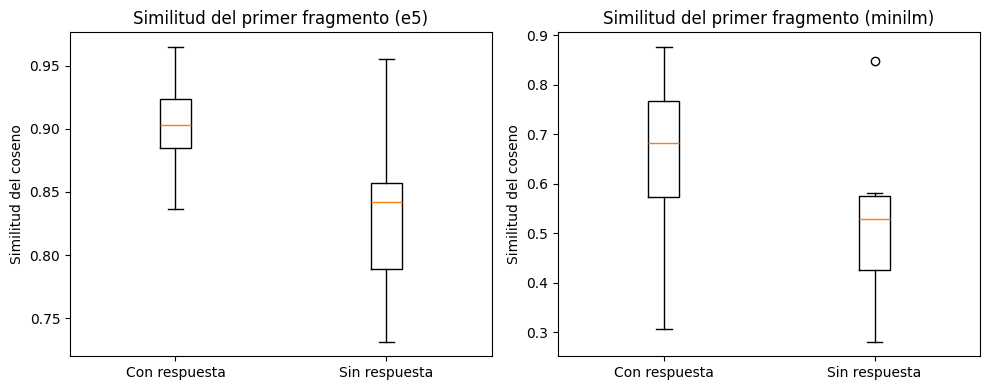

In [ ]:
df_res["tiene_respuesta"] = df_res["ids_relevantes"].map(len) > 0

rechazos = pd.DataFrame(
    {
        "Rechazos indebidos (preguntas con respuesta)": df_res[df_res["tiene_respuesta"]].groupby("embedding")["rechazo"].sum(),
        "Rechazos correctos (preguntas sin respuesta)": df_res[~df_res["tiene_respuesta"]].groupby("embedding")["rechazo"].sum(),
    }
)
total_con = int(df_res[df_res["tiene_respuesta"]].groupby("embedding").size().iloc[0])
total_sin = int(df_res[~df_res["tiene_respuesta"]].groupby("embedding").size().iloc[0])
print(f"Preguntas con respuesta en la base: {total_con} | sin respuesta: {total_sin}\n")
print(rechazos.to_string())

print("\n=== Similitud del primer fragmento recuperado ===")
tabla_sim = (df_res.groupby(["embedding", "tiene_respuesta"])["sim_top1"]
             .agg(["min", "mean", "max"]).round(3))
print(tabla_sim.to_string())

# Gráfico: ¿se separan las preguntas con respuesta de las que no la tienen?
fig, ejes = plt.subplots(1, 2, figsize=(10, 4), sharey=False)
for eje, alias in zip(ejes, ["e5", "minilm"]):
    datos = df_res[df_res["embedding"] == alias]
    eje.boxplot([datos[datos["tiene_respuesta"]]["sim_top1"], datos[~datos["tiene_respuesta"]]["sim_top1"]])
    eje.set_xticks([1, 2])
    eje.set_xticklabels(["Con respuesta", "Sin respuesta"])
    eje.set_title(f"Similitud del primer fragmento ({alias})")
    eje.set_ylabel("Similitud del coseno")
plt.tight_layout()
plt.show()

### d.3 Respuestas generadas
Se muestra, para cada pregunta, la respuesta de referencia y las respuestas de los dos
chatbots, para valorarlas **a mano**.

In [ ]:
def mostrar_para_revisar(desde=0, hasta=8):
    """Muestra las preguntas de evaluación entre las posiciones desde y hasta."""
    for e in dataset_eval[desde:hasta]:
        e5 = df_res[(df_res["embedding"] == "e5") & (df_res["id"] == e["id"])].iloc[0]
        mi = df_res[(df_res["embedding"] == "minilm") & (df_res["id"] == e["id"])].iloc[0]
        print("=" * 90)
        print(f"[{e['id']}] ({e['tipo']}) {e['pregunta']}")
        print(f"REFERENCIA : {e['respuesta_referencia']}")
        print(f"E5         : {e5['respuesta_generada']}")
        print(f"             (recuperó {e5['ids_recuperados']}, relevantes {e['ids_relevantes']})")
        print(f"MiniLM     : {mi['respuesta_generada']}")
        print(f"             (recuperó {mi['ids_recuperados']}, relevantes {e['ids_relevantes']})")


# Ver de a grupos para no saturar la pantalla; cambiar los números para ver los demás
mostrar_para_revisar(0, 31)

[E01] (paráfrasis) ¿Cuánto tiempo puedo usar la constancia de cumplimiento tributario antes de que venza?
REFERENCIA : Tiene una validez de 30 días.
E5         : La Constancia de Cumplimiento Tributario tiene una validez de 30 días.
             (recuperó [1, 2, 18], relevantes [1])
MiniLM     : La constancia de cumplimiento tributario tiene una validez de 30 días.
             (recuperó [1, 9, 18], relevantes [1])
[E02] (paráfrasis) ¿Qué área municipal emite la constancia tributaria para habilitar?
REFERENCIA : La emite el Departamento de Recaudación de la Municipalidad.
E5         : La constancia tributaria para habilitar la emite el Departamento de Recaudación de la Municipalidad.
             (recuperó [17, 2, 1], relevantes [2])
MiniLM     : No hay información disponible en la base de conocimiento para responder esta pregunta.
             (recuperó [13, 10, 11], relevantes [2])
[E03] (paráfrasis) ¿Para qué tengo que anotarme en ARBA antes de la habilitación?
REFERENCIA : Para ins

In [ ]:
ETIQUETAS_VALIDAS = {"correcta", "parcial", "incorrecta", "rechazo correcto",
                     "rechazo indebido", "alucinación", "revisar"}

# Valoración inicial automática, solo para lo que se puede decidir sin leer la respuesta:
# - pregunta sin respuesta + rechazó  -> "rechazo correcto"
# - pregunta sin respuesta + respondió -> "alucinación" (revisar a mano si de verdad inventó)
# - pregunta con respuesta + rechazó   -> "rechazo indebido"
# - pregunta con respuesta + respondió -> "revisar" (la valoración la hace una persona)
valoraciones = {}
for e in dataset_eval:
    par = {}
    for alias in ("e5", "minilm"):
        fila = df_res[(df_res["embedding"] == alias) & (df_res["id"] == e["id"])].iloc[0]
        if not e["ids_relevantes"]:
            par[alias] = "rechazo correcto" if fila["rechazo"] else "alucinación"
        else:
            par[alias] = "rechazo indebido" if fila["rechazo"] else "revisar"
    valoraciones[e["id"]] = par


def valorar_lote(lote):
    """Actualiza valoraciones. Formato: {"E01": ("correcta", "parcial"), ...} -> (E5, MiniLM)."""
    for id_pregunta, (val_e5, val_minilm) in lote.items():
        for alias, valor in (("e5", val_e5), ("minilm", val_minilm)):
            if valor not in ETIQUETAS_VALIDAS:
                raise ValueError(f"{id_pregunta}: valoración no válida '{valor}'. Usar: {sorted(ETIQUETAS_VALIDAS)}")
            valoraciones[id_pregunta][alias] = valor


pendientes = [i for i, v in valoraciones.items() if "revisar" in v.values()]
print(f"Preguntas que todavía hay que valorar a mano: {len(pendientes)}")
print(pendientes)

Preguntas que todavía hay que valorar a mano: 25
['E01', 'E02', 'E03', 'E04', 'E05', 'E06', 'E07', 'E08', 'E09', 'E10', 'E11', 'E12', 'E13', 'E14', 'E15', 'E16', 'E17', 'E18', 'E19', 'E20', 'E21', 'E22', 'E23', 'E24', 'E25']


In [ ]:
valorar_lote({
    "E01": ("correcta", "correcta"),
    "E02": ("correcta", "rechazo indebido"),
    "E03": ("correcta", "correcta"),
    "E04": ("correcta", "rechazo indebido"),
    "E05": ("parcial", "correcta"),
    "E06": ("correcta", "correcta"),
    "E07": ("correcta", "correcta"),
    "E08": ("correcta", "rechazo indebido"),
    "E09": ("correcta", "correcta"),
    "E10": ("correcta", "correcta"),
    "E11": ("correcta", "correcta"),
    "E12": ("correcta", "correcta"),
    "E13": ("correcta", "correcta"),
    "E14": ("correcta", "correcta"),
    "E15": ("parcial", "parcial"),
    "E16": ("correcta", "correcta"),
    "E17": ("correcta", "correcta"),
    "E18": ("correcta", "correcta"),
    "E19": ("correcta", "correcta"),
    "E20": ("correcta", "rechazo indebido"),
    "E21": ("correcta", "correcta"),
    "E22": ("parcial", "parcial"),
    "E23": ("parcial", "parcial"),
    "E24": ("parcial", "rechazo indebido"),
    "E25": ("parcial", "rechazo indebido"),
    "E26": ("rechazo correcto", "rechazo correcto"),
    "E27": ("rechazo correcto", "rechazo correcto"),
    "E28": ("rechazo correcto", "rechazo correcto"),
    "E29": ("rechazo correcto", "rechazo correcto"),
    "E30": ("rechazo correcto", "rechazo correcto"),
    "E31": ("rechazo correcto", "rechazo correcto"),
})

pendientes = [i for i, v in valoraciones.items() if "revisar" in v.values()]
print("Sin valorar todavía:", pendientes or "ninguna")

Sin valorar todavía: ninguna


=== Cantidad de respuestas por valoración ===
embedding         e5  minilm
valoración                  
correcta          19      16
parcial            6       3
rechazo correcto   6       6
rechazo indebido   0       6

=== Puntaje promedio (1 = correcta, 0,5 = parcial, 0 = error) ===
embedding
e5        0.903
minilm    0.758

=== Puntaje promedio por tipo de pregunta ===
embedding                     e5  minilm
tipo                                    
fuera de tema               1.00    1.00
informal                    1.00    0.50
multi-entrada               0.50    0.25
paráfrasis                  0.95    0.82
tema cercano sin respuesta  1.00    1.00


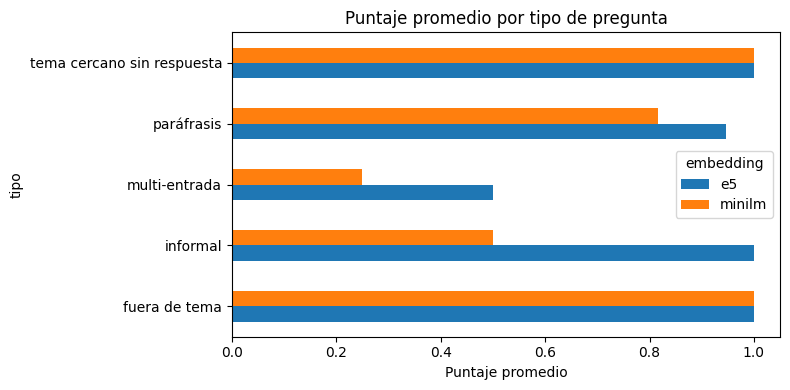

In [ ]:
PUNTAJE = {"correcta": 1.0, "rechazo correcto": 1.0, "parcial": 0.5,
           "incorrecta": 0.0, "rechazo indebido": 0.0, "alucinación": 0.0, "revisar": np.nan}

# Control: las valoraciones "revisar" no se cuentan en el promedio, así que si quedan
# pendientes el resultado sería engañoso. Completar la celda donde se llama a valorar_lote antes de interpretar esta tabla.
sin_valorar = [i for i, v in valoraciones.items() if "revisar" in v.values()]
if sin_valorar:
    print(f"ATENCIÓN: faltan valorar {len(sin_valorar)} preguntas ({sin_valorar}).")
    print("Los promedios de abajo NO incluyen esas respuestas y todavía no sirven para comparar.\n")

filas = []
for e in dataset_eval:
    for alias in ("e5", "minilm"):
        valor = valoraciones[e["id"]][alias]
        filas.append({"embedding": alias, "id": e["id"], "tipo": e["tipo"],
                      "valoración": valor, "puntaje": PUNTAJE[valor]})
df_val = pd.DataFrame(filas)

print("=== Cantidad de respuestas por valoración ===")
print(df_val.pivot_table(index="valoración", columns="embedding", values="id", aggfunc="count", fill_value=0).to_string())

print("\n=== Puntaje promedio (1 = correcta, 0,5 = parcial, 0 = error) ===")
print(df_val.groupby("embedding")["puntaje"].mean().round(3).to_string())

print("\n=== Puntaje promedio por tipo de pregunta ===")
print(df_val.pivot_table(index="tipo", columns="embedding", values="puntaje", aggfunc="mean").round(2).to_string())

# Gráfico del puntaje por tipo de pregunta
df_val.pivot_table(index="tipo", columns="embedding", values="puntaje", aggfunc="mean").plot(
    kind="barh", figsize=(8, 4), title="Puntaje promedio por tipo de pregunta")
plt.xlabel("Puntaje promedio")
plt.tight_layout()
plt.show()

In [ ]:
distintos = [e for e in dataset_eval
             if valoraciones[e["id"]]["e5"] != valoraciones[e["id"]]["minilm"]]
print(f"Preguntas en las que las valoraciones de E5 y MiniLM difieren: {len(distintos)}\n")
for e in distintos:
    v = valoraciones[e["id"]]
    print(f"[{e['id']}] ({e['tipo']}) {e['pregunta']}  ->  E5: {v['e5']} | MiniLM: {v['minilm']}")

Preguntas en las que las valoraciones de E5 y MiniLM difieren: 7

[E02] (paráfrasis) ¿Qué área municipal emite la constancia tributaria para habilitar?  ->  E5: correcta | MiniLM: rechazo indebido
[E04] (paráfrasis) ¿Con qué datos me registro en Mi cuenta ciudadano?  ->  E5: correcta | MiniLM: rechazo indebido
[E05] (paráfrasis) ¿Qué tengo que hacer después de entrar a Habilitaciones Comerciales en mi cuenta?  ->  E5: parcial | MiniLM: correcta
[E08] (paráfrasis) ¿Dónde pido el turno una vez que la consulta fue aprobada?  ->  E5: correcta | MiniLM: rechazo indebido
[E20] (informal) donde saco turno  ->  E5: correcta | MiniLM: rechazo indebido
[E24] (multi-entrada) ¿Qué gestiones se hacen en el Departamento de Recaudación durante el trámite?  ->  E5: parcial | MiniLM: rechazo indebido
[E25] (multi-entrada) Contame los pasos principales desde que me registro hasta que me dan el certificado en trámite.  ->  E5: parcial | MiniLM: rechazo indebido


### d.4 Conclusiones y elección del modelo de embeddings

**Resumen de lo realizado.** Probé dos chatbots idénticos (mismo LLM, `Qwen3-4B-Instruct-2507`, y misma base de conocimiento en Chroma) que solo se diferencian en el modelo de embeddings: `multilingual-e5-base` (E5) y `paraphrase-multilingual-MiniLM-L12-v2` (MiniLM). Los evalué con 31 preguntas nuevas: 25 con respuesta en la base y 6 sin respuesta.

**Resultados.**

| | E5 | MiniLM |
|---|---|---|
| Hit@1 (25 preguntas con respuesta) | 0,76 | 0,76 |
| Hit@3 | 1,00 | 0,84 |
| MRR | 0,87 | 0,79 |
| Recall@3 | 0,92 | 0,75 |
| Respuestas correctas (de 31) | 25 | 22 |
| Respuestas parciales | 6 | 3 |
| Rechazos indebidos | 0 | 6 |
| Rechazos correctos (de 6 sin respuesta) | 6 | 6 |
| Puntaje promedio (1 = correcta, 0,5 = parcial) | 0,90 | 0,76 |

**Recuperación.** En el primer lugar los dos acertaron lo mismo (Hit@1 = 0,76), pero E5 siempre trajo el fragmento correcto entre los tres recuperados (Hit@3 = 1,00), mientras que MiniLM falló en 4 preguntas (E02, E04, E08 y E20) y no lo trajo en ninguna posición. Son paráfrasis con palabras distintas a las de la base (por ejemplo "área municipal" por "dónde se pide") y una consulta informal ("donde saco turno"). Por tipo de pregunta, en las informales E5 acertó siempre en el primer lugar (1,00 contra 0,50 de MiniLM) y en las paráfrasis tuvo mejor Hit@3 (1,00 contra 0,84). En las multi-entrada, en cambio, MiniLM puso una entrada relevante en primer lugar en las 4 preguntas y E5 en 2 de 4 (Hit@1 de 1,00 contra 0,50), aunque con tres fragmentos ambos recuperaron alguna entrada relevante en todas (Hit@3 = 1,00). El Recall@3 fue mayor en E5 (0,92 contra 0,75), es decir que recuperó una proporción más alta de las entradas necesarias. La diferencia aparece en el Hit@3 y no en el Hit@1 porque el LLM logra responder bien aunque el fragmento correcto no sea el primero, siempre que esté entre los recuperados.

**Rechazos.** Los dos chatbots rechazaron correctamente las 6 preguntas sin respuesta, incluidas las de tema cercano (costo de la tasa, licencia de conducir, tiempo de inspección y horario de atención), y ninguno inventó información en esos casos. En cambio, MiniLM rechazó indebidamente 6 preguntas que sí tenían respuesta. (La detección automática de rechazos de la sección d.2 contó 1 rechazo indebido en E5 y 7 en MiniLM; al leer las respuestas quedan 0 y 6, porque en E05 y E23 el chatbot sí respondió y después agregó la frase de rechazo.) En 4 de ellas la causa fue la recuperación (el fragmento correcto no estaba en el contexto). En las otras 2 (E24 y E25) el contexto tenía información útil y aun así el LLM respondió que no tenía información, lo que indica que el prompt es demasiado estricto cuando la información está incompleta.

**Errores del LLM que no dependen del embedding.**
- En E15 ("¿Siempre piden el curso de manipulador de alimentos?") los dos chatbots empezaron con "No, siempre piden...", que invierte el sentido, aunque el resto de la respuesta era correcta.
- En E05 (E5) y E23 (MiniLM) el chatbot dio una respuesta y a continuación agregó la frase de "no hay información", contradiciéndose. Por eso la detección automática de rechazos marcó como errores respuestas que en parte eran válidas.
- En E22, E5 agregó una explicación del nombre de ARBA que no estaba en el contexto y que no corresponde (inventó datos).

**Preguntas multi-entrada.** Fueron las más difíciles. Con `k = 3` no alcanzan los fragmentos cuando la respuesta necesita 4 o 6 entradas de la base. E5 dio respuestas parciales en las 4 (omitió la constancia de Recaudación en E22 y E24, y la matafuego y la eléctrica en E23, por ejemplo), mientras que MiniLM dio 2 parciales y 2 rechazos.

**Elección.** Elegiría **E5 (`multilingual-e5-base`)** para esta aplicación porque tuvo mejor recuperación (Hit@3 y MRR), no rechazó ninguna pregunta que sí tenía respuesta y obtuvo mayor puntaje (0,90 contra 0,76). Su costo es que es un modelo más grande (278 millones de parámetros contra 118 millones) y de vectores de mayor dimensión (768 contra 384), pero en la práctica no resultó más lento: el chatbot con E5 tardó en promedio 2,0 segundos por respuesta y el de MiniLM 2,5 segundos, porque la mayor parte del tiempo la consume la generación del LLM y no la búsqueda. Para una consulta que busca ayudar a una persona con un trámite, rechazar una pregunta que sí se puede responder es un error más molesto que una respuesta parcial.

**Qué mejoraría.**
- Aumentar `k` (por ejemplo a 5) para las preguntas que combinan varias entradas.
- Ajustar el prompt: pedir que no agregue la frase de rechazo si ya respondió, y que responda con lo que encuentre aclarando qué falta cuando el contexto es incompleto.
- Agregar a la base más formas de preguntar lo mismo para cada entrada.
- Probar un umbral de similitud para rechazar antes de llamar al LLM, aunque con estos datos no sería confiable: la similitud del primer fragmento se superpone bastante entre las preguntas con y sin respuesta. En E5 va de 0,836 a 0,965 con respuesta (promedio 0,904) y de 0,732 a 0,956 sin respuesta (promedio 0,834); en MiniLM, de 0,308 a 0,877 con respuesta (promedio 0,660) y de 0,282 a 0,849 sin respuesta (promedio 0,529). Además, E5 da similitudes altas incluso para preguntas sin relación con el tema (sus vectores se concentran en un rango estrecho), por lo que su valor absoluto es difícil de interpretar. En este trabajo el rechazo lo resolvió mejor el LLM (6 de 6 en los dos chatbots) que lo que habría resuelto un umbral.

**Limitaciones.** Solo hay 31 preguntas, así que una diferencia de una o dos respuestas no es concluyente. Las preguntas y las respuestas de referencia las redacté yo a partir de la misma página que usé para la base de conocimiento. La valoración de las respuestas es subjetiva y la hizo una sola persona. Y todos los resultados corresponden a un único LLM con generación sin azar, por lo que no se puede separar con certeza el efecto del embedding del efecto del prompt.

> **Consigna e) BONUS (opcional).** Evalúe el chatbot creado en c) para los modelos de embeddings elegidos y usados en d) usando el dataset a) con las métricas context precision y context recall. Puede probar usar la librería ragas o implementar Ud. mismo el cálculo de dichas métricas. Dado sus resultados: ¿refuerza o no sus conclusiones realizadas en d)? Explique los resultados obtenidos y agregue sus conclusiones.

## e) BONUS: evaluación del retrieval con *context precision* y *context recall*

Estas dos métricas evalúan solo la **recuperación** (los fragmentos que el chatbot le entrega
al LLM), sin mirar la respuesta generada:

- **Context recall:** ¿qué proporción de la información necesaria para responder fue
  efectivamente recuperada? Se calcula como
  `entradas relevantes recuperadas / entradas relevantes totales`.
- **Context precision:** ¿los fragmentos relevantes aparecen **primero** en el ranking, y no
  mezclados con fragmentos irrelevantes? Se calcula como en `ragas`:
  `Context Precision@K = (Σ de k=1 a K de  Precision@k × v_k) / (cantidad de relevantes en el top K)`,
  donde `v_k` vale 1 si el fragmento en la posición `k` es relevante y 0 si no. Si ningún
  fragmento relevante aparece entre los K recuperados, vale 0.

**Ejemplo (una entrada relevante):** si aparece en la posición 1, la precisión es 1,00; en la
posición 2, 0,50; en la posición 3, 0,33.

**Cómo se implementa aquí.** La librería `ragas` usa un LLM como juez para decidir si cada
fragmento es relevante. En este trabajo implementé las métricas yo mismo y decido la
relevancia con los `ids_relevantes` que marqué a mano en el dataset de evaluación. Es más
simple, rápido y reproducible, pero depende de que esas marcas estén bien hechas.

**Alcance.** Solo se calculan para las 25 preguntas que tienen respuesta en la base de
conocimiento: en las 6 que no la tienen no hay fragmentos relevantes, así que las métricas
no están definidas.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def context_recall(ids_relevantes, ids_recuperados):
    """Proporción de las entradas relevantes que aparecen entre las recuperadas."""
    relevantes = set(ids_relevantes)
    return len(relevantes & set(ids_recuperados)) / len(relevantes)


def context_precision(ids_relevantes, ids_recuperados):
    """Context Precision@K (definición de ragas): premia que lo relevante aparezca primero."""
    relevantes = set(ids_relevantes)
    acertados = 0          # cantidad de relevantes vistos hasta la posición k
    suma_precisiones = 0.0
    for posicion, kb_id in enumerate(ids_recuperados, start=1):
        if kb_id in relevantes:
            acertados += 1
            suma_precisiones += acertados / posicion   # Precision@k en esa posición
    return suma_precisiones / acertados if acertados else 0.0


def precision_simple(ids_relevantes, ids_recuperados):
    """Precision@K clásica: relevantes recuperados / K (no mira el orden)."""
    relevantes = set(ids_relevantes)
    return sum(1 for i in ids_recuperados if i in relevantes) / len(ids_recuperados)


def recall_alcanzable(ids_relevantes, ids_recuperados):
    """Recall dividido por el máximo posible con K fragmentos (si hay más de K relevantes)."""
    maximo = min(1.0, len(ids_recuperados) / len(ids_relevantes))
    return context_recall(ids_relevantes, ids_recuperados) / maximo


# Pruebas rápidas de las funciones con casos conocidos
assert context_precision([1], [1, 2, 3]) == 1.0
assert abs(context_precision([1], [2, 1, 3]) - 0.5) < 1e-9
assert abs(context_precision([1], [2, 3, 1]) - 1 / 3) < 1e-9
assert context_precision([1], [2, 3, 4]) == 0.0
assert context_recall([1, 2, 3, 4], [1, 2, 9]) == 0.5
print("Las funciones de las métricas pasan las pruebas básicas.")

Las funciones de las métricas pasan las pruebas básicas.


In [ ]:
filas = []
for _, f in df_res[df_res["tiene_respuesta"]].iterrows():
    rel, rec = f["ids_relevantes"], f["ids_recuperados"]
    filas.append(
        {
            "embedding": f["embedding"],
            "id": f["id"],
            "tipo": f["tipo"],
            "relevantes": rel,
            "recuperados": rec,
            "context_recall": context_recall(rel, rec),
            "context_precision": context_precision(rel, rec),
            "precision@K": precision_simple(rel, rec),
            "recall_alcanzable": recall_alcanzable(rel, rec),
        }
    )

df_e = pd.DataFrame(filas)
print(f"Preguntas evaluadas por embedding: {len(df_e) // 2} | K = {K}")

Preguntas evaluadas por embedding: 25 | K = 3


=== Promedio por embedding ===
           context_precision  context_recall  precision@K  recall_alcanzable
embedding                                                                   
e5                     0.877           0.917        0.373              0.940
minilm                 0.780           0.747        0.307              0.767

=== Context precision por tipo de pregunta ===
embedding         e5  minilm
tipo                        
informal       1.000   0.500
multi-entrada  0.729   0.958
paráfrasis     0.895   0.772

=== Context recall por tipo de pregunta ===
embedding         e5  minilm
tipo                        
informal       1.000   0.500
multi-entrada  0.479   0.417
paráfrasis     1.000   0.842


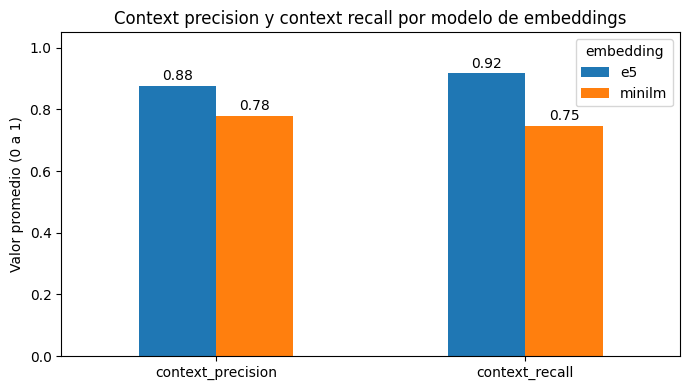

In [ ]:
metricas = ["context_precision", "context_recall"]

print("=== Promedio por embedding ===")
resumen_e = df_e.groupby("embedding")[metricas + ["precision@K", "recall_alcanzable"]].mean().round(3)
print(resumen_e.to_string())

print("\n=== Context precision por tipo de pregunta ===")
print(df_e.pivot_table(index="tipo", columns="embedding", values="context_precision", aggfunc="mean").round(3).to_string())

print("\n=== Context recall por tipo de pregunta ===")
print(df_e.pivot_table(index="tipo", columns="embedding", values="context_recall", aggfunc="mean").round(3).to_string())

# Gráfico comparativo
ax = resumen_e[metricas].T.plot(kind="bar", figsize=(7, 4), rot=0)
ax.set_title("Context precision y context recall por modelo de embeddings")
ax.set_ylabel("Valor promedio (0 a 1)")
ax.set_ylim(0, 1.05)
for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt="%.2f", padding=2)
plt.tight_layout()
plt.show()

In [ ]:
print("Context precision < 1 o context recall < 1, por embedding:\n")
for alias in ["e5", "minilm"]:
    peores = df_e[(df_e["embedding"] == alias)
                  & ((df_e["context_precision"] < 1) | (df_e["context_recall"] < 1))]
    print(f"===== {alias}: {len(peores)} de {len(df_e[df_e['embedding'] == alias])} preguntas =====")
    for _, f in peores.iterrows():
        print(f"[{f['id']}] ({f['tipo']}) relevantes {f['relevantes']} | recuperó {f['recuperados']} "
              f"| precision {f['context_precision']:.2f} | recall {f['context_recall']:.2f}")
    print()

Context precision < 1 o context recall < 1, por embedding:

===== e5: 8 de 25 preguntas =====
[E02] (paráfrasis) relevantes [2] | recuperó [17, 2, 1] | precision 0.50 | recall 1.00
[E04] (paráfrasis) relevantes [4] | recuperó [6, 4, 10] | precision 0.50 | recall 1.00
[E05] (paráfrasis) relevantes [5] | recuperó [0, 5, 7] | precision 0.50 | recall 1.00
[E08] (paráfrasis) relevantes [8] | recuperó [7, 8, 9] | precision 0.50 | recall 1.00
[E22] (multi-entrada) relevantes [1, 2, 3, 9] | recuperó [9, 8, 18] | precision 1.00 | recall 0.25
[E23] (multi-entrada) relevantes [13, 14, 16] | recuperó [11, 16, 13] | precision 0.58 | recall 0.67
[E24] (multi-entrada) relevantes [2, 17] | recuperó [4, 8, 17] | precision 0.33 | recall 0.50
[E25] (multi-entrada) relevantes [4, 5, 7, 8, 17, 18] | recuperó [18, 4, 8] | precision 1.00 | recall 0.50

===== minilm: 10 de 25 preguntas =====
[E02] (paráfrasis) relevantes [2] | recuperó [13, 10, 11] | precision 0.00 | recall 0.00
[E04] (paráfrasis) relevantes 

In [ ]:
PUNTAJE_RESPUESTA = {"correcta": 1.0, "parcial": 0.5, "incorrecta": 0.0,
                     "rechazo indebido": 0.0, "alucinación": 0.0}

df_e["valoracion_respuesta"] = [valoraciones[f["id"]][f["embedding"]] for _, f in df_e.iterrows()]
df_e["puntaje_respuesta"] = df_e["valoracion_respuesta"].map(PUNTAJE_RESPUESTA)

print("Promedio del puntaje de la respuesta según el context recall de la pregunta:")
print(df_e.groupby(["embedding", "context_recall"])["puntaje_respuesta"]
      .agg(["count", "mean"]).round(2).to_string())

Promedio del puntaje de la respuesta según el context recall de la pregunta:
                          count  mean
embedding context_recall             
e5        0.250000            1  0.50
          0.500000            2  0.50
          0.666667            1  0.50
          1.000000           21  0.95
minilm    0.000000            4  0.00
          0.333333            2  0.25
          0.500000            2  0.25
          1.000000           17  0.97


### e.1 Resultados y conclusiones

**Qué se midió.** Evalué solo la recuperación de fragmentos (sin mirar la respuesta del LLM) con dos métricas, implementadas por mí a partir de los `ids_relevantes` del dataset de evaluación, para las 25 preguntas que tienen respuesta en la base de conocimiento (K = 3):
- **Context recall:** qué proporción de las entradas necesarias recuperó el chatbot.
- **Context precision:** si las entradas relevantes aparecen primero en el ranking (definición de `ragas`).

**Resultados.** 

| | E5 | MiniLM |
|---|---|---|
| Context recall | 0,92 | 0,75 |
| Context precision | 0,88 | 0,78 |

| Tipo de pregunta | Recall E5 | Recall MiniLM | Precision E5 | Precision MiniLM |
|---|---|---|---|---|
| Paráfrasis (19) | 1,00 | 0,84 | 0,90 | 0,77 |
| Informales (2) | 1,00 | 0,50 | 1,00 | 0,50 |
| Multi-entrada (4) | 0,48 | 0,42 | 0,73 | 0,96 |

**¿Refuerzan estos resultados las conclusiones de d)? Sí, en lo principal.**
- **E5 recupera mejor.** Tiene mayor context recall (0,92 contra 0,75) y mayor context precision (0,88 contra 0,78), lo mismo que ya había observado con Hit@3 (1,00 contra 0,84) y MRR (0,87 contra 0,79). Las cuatro métricas apuntan al mismo modelo.
- **La recuperación explica la calidad de las respuestas.** Cuando el recall de una pregunta fue 1,00, las respuestas fueron casi siempre correctas (puntaje promedio de 0,95 en E5 y 0,97 en MiniLM). Cuando el recall fue 0, las respuestas de MiniLM fueron todas rechazos indebidos (puntaje 0,00 en 4 preguntas: E02, E04, E08 y E20). Con recall parcial (entre 0,25 y 0,67) las respuestas fueron parciales o rechazos. Esto confirma lo que concluí en d): los rechazos indebidos de MiniLM se debieron principalmente a que no recuperó el fragmento correcto, y no a un problema del LLM.
- **Las paráfrasis e informales son donde más se diferencian:** E5 recuperó todas las entradas necesarias (recall 1,00), mientras que MiniLM falló en 4 de las 21 preguntas de estos tipos.

**Un matiz que no aparecía en d).** En las preguntas multi-entrada, MiniLM tuvo mayor context precision (0,96 contra 0,73): cuando recuperó entradas relevantes, las puso primero. Con E5 aparecieron fragmentos irrelevantes en los primeros lugares de E23 y E24. En cambio, el recall de ambos en ese tipo de pregunta fue bajo (0,48 y 0,42). Son solo 4 preguntas, así que esta diferencia no es concluyente. Además, las dos métricas miden cosas distintas: la precisión no penaliza que falten entradas (por ejemplo, en E22 E5 tuvo precisión 1,00 pero recall 0,25).

**Limitación de K.** Con K = 3 es imposible recuperar todas las entradas cuando una pregunta necesita más de tres (E25 necesita 6, por lo que su recall máximo posible es 0,50). Por eso calculé también un "recall alcanzable" (recall dividido por el máximo posible con K fragmentos): 0,94 para E5 y 0,77 para MiniLM. La conclusión no cambia, pero muestra que parte del recall bajo en las preguntas multi-entrada se debe al valor de K y no al modelo.

**Limitaciones de la evaluación.**
- La relevancia la decidí yo a mano con los `ids_relevantes`; `ragas` en cambio usa un LLM como juez, por lo que mis resultados no son directamente comparables con los de esa librería.
- Hay pocas preguntas por tipo (2 informales y 4 multi-entrada), por lo que los promedios de esos grupos son poco confiables.
- No se pueden calcular estas métricas para las 6 preguntas sin respuesta en la base, porque no tienen fragmentos relevantes.

> **Consigna f) BONUS (opcional).** Evalúe el modelo LLM usado para el chatbot creado en c) con el modelo de embedding que mejor le haya resultado en d) usando el dataset a). Use las métricas Answer Relevancy y Faithfulness. Puede probar usar la librería ragas o implementar Ud. mismo el cálculo de dichas métricas. Explique los resultados obtenidos y agregue sus conclusiones.

**Esta consigna opcional no fue resuelta en este trabajo.**

> **Consigna g) REFERENCIAS.** Es obligatorio citar las fuentes de todo material utilizado para su TP incluido chats con IA generativa. Al final en su apartado Referencias liste todas las fuentes consultadas. Por ejemplo si mantuvo una conversación con ChatGPT puede agregar el enlace compartido a dicha conversación.

## g) Referencias

### Fuente de los datos
- Municipio de Bahía Blanca. (s. f.). *Recomendaciones para realizar el trámite* [Habilitaciones comerciales]. https://www.bahia.gob.ar/tramites/habilitaciones/comerciales/recomendaciones-para-realizar-el-tramite/. Consultado el 11/10/2026 (TP3) y nuevamente en noviembre de 2026 (TP5). Contenido con licencia Creative Commons Reconocimiento 2.5 Argentina.

### Modelos utilizados
- Qwen Team. (2025). *Qwen3-4B-Instruct-2507* [Modelo de lenguaje, licencia Apache-2.0]. Hugging Face. https://huggingface.co/Qwen/Qwen3-4B-Instruct-2507
- Wang, L., Yang, N., Huang, X., Yang, L., Majumder, R., & Wei, F. (s. f.). *multilingual-e5-base* [Modelo de embeddings, licencia MIT]. Hugging Face. https://huggingface.co/intfloat/multilingual-e5-base
- Sentence-Transformers. (s. f.). *paraphrase-multilingual-MiniLM-L12-v2* [Modelo de embeddings]. Hugging Face. https://huggingface.co/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2
- Explosion. (s. f.). *Modelos de spaCy para español* (es_core_news_sm y es_core_news_md), usados en la Parte 1. https://spacy.io/models/es

### Artículos y reportes técnicos
- Yang, A., et al. (2025). *Qwen3 Technical Report*. arXiv:2505.09388. https://arxiv.org/abs/2505.09388
- Wang, L., Yang, N., Huang, X., Yang, L., Majumder, R., & Wei, F. (2024). *Multilingual E5 Text Embeddings: A Technical Report*. arXiv:2402.05672. https://arxiv.org/abs/2402.05672
- Reimers, N., & Gurevych, I. (2020). *Making Monolingual Sentence Embeddings Multilingual using Knowledge Distillation*. arXiv:2004.09813. https://arxiv.org/abs/2004.09813
- Reimers, N., & Gurevych, I. (2019). *Sentence-BERT: Sentence Embeddings using Siamese BERT-Networks*. arXiv:1908.10084. https://arxiv.org/abs/1908.10084
- Lewis, P., et al. (2020). *Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks*. arXiv:2005.11401. https://arxiv.org/abs/2005.11401

### Documentación de las herramientas
- Sentence-Transformers. (s. f.). *Documentación de Sentence Transformers*. https://www.sbert.net
- Hugging Face. (s. f.). *Documentación de Transformers*. https://huggingface.co/docs/transformers
- Hugging Face. (s. f.). *User access tokens*. https://huggingface.co/docs/hub/security-tokens
- Chroma. (s. f.). *Chroma Docs*. https://docs.trychroma.com
- Ragas. (s. f.). *Documentación de las métricas Context Precision y Context Recall* (definiciones en las que se basa la consigna e). https://docs.ragas.io. Las métricas se implementaron sin la librería.
- scikit-learn developers. (s. f.). *scikit-learn: Machine learning in Python* (`TfidfVectorizer` y `cosine_similarity`, usados en la Parte 1). https://scikit-learn.org

### Trabajo propio anterior y material de la materia
- Alanis, C. (2026). *TP3: Chatbots basados en recuperación de la información*. Corresponde a la Parte 1 de este mismo notebook; el dataset de preguntas y respuestas creado en ese TP es la base de conocimiento de este trabajo.
- Material de clase de la materia Procesamiento del Habla (vectorización de texto, TF-IDF y word embeddings).

### Uso de inteligencia artificial generativa
- Anthropic. (2026). *Claude* [Modelo de lenguaje de gran tamaño]. https://claude.ai. Conversación compartida: **[COMPLETAR ENLACE A LA CONVERSACIÓN COMPARTIDA]**

**Declaración de uso.** Para este trabajo usé el asistente de IA Claude, de Anthropic, en una misma conversación que incluye también el desarrollo del TP3. El asistente:
- propuso y justificó los modelos (LLM y embeddings) a partir de sus fichas técnicas;
- escribió el código base de las consignas a) a e) (dataset de evaluación, clases `Embedder`, `LLM` y `ChatBot`, evaluación comparativa y métricas del bonus);
- propuso las valoraciones de las respuestas de los chatbots a partir de las respuestas que le compartí, y redactó borradores de las conclusiones de d) y e) y de esta sección de referencias;
- armó las modificaciones del archivo del notebook (consignas copiadas, conclusiones y referencias).

Lo que hice yo: ejecuté todo el código en Google Colab; detecté y corregí un error en las celdas de control del dataset de evaluación; compartí con el asistente los resultados de las celdas para analizarlos; cargué las valoraciones de las respuestas en el notebook; y decidí qué consignas resolver (a a e) y cuáles no (el bonus f).